In [1]:
import sys
print(sys.executable)

/Users/ahn/micromamba/envs/mpdag_env/bin/python


# Results on noised data

In [3]:
"""
Load all CSVs from experiment_runs/normal_tar_er2_d10_25_mu01_05,
parse metadata from filenames, build a unified DataFrame, then plot
each metric vs complexity_metric for each noise level (false_ratio).

File naming convention:  n{N}_deg{D}_d{d}_fr{fr}.csv
  N   = n_samples (but also in the CSV)
  D   = exp_degree
  d   = observed variables
  fr  = false_ratio (noise level)
"""

import re
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# ── Config ───────────────────────────────────────────────────────────────────
DIR        = "experiment_runs/normal_tar_er2_d10_25_mu01_05"
OUTPUT_DIR = "plots_noised"
os.makedirs(OUTPUT_DIR, exist_ok=True)

NOISE_LEVELS = [0.1, 0.2, 0.3, 0.5]   # false_ratio values to plot

METRICS = ["f1", "int_dist"]
METRIC_LABELS = {"f1": "F1 Score", "int_dist": "Int. Distance"}

# ── 1. Load & concatenate all CSVs ──────────────────────────────────────────
pattern = os.path.join(DIR, "**", "*.csv")
files   = glob.glob(pattern, recursive=True)
if not files:
    # also try flat
    files = glob.glob(os.path.join(DIR, "*.csv"))

print(f"Found {len(files)} CSV files.")

dfs = []
for fpath in files:
    fname = os.path.basename(fpath)
    # parse false_ratio from filename  e.g. n100_deg2_d10_fr0.1.csv
    match = re.search(r"fr([0-9]+\.?[0-9]*)", fname)
    if match is None:
        print(f"  WARNING: could not parse fr from {fname}, skipping.")
        continue
    false_ratio = float(match.group(1))

    df_tmp = pd.read_csv(fpath)
    df_tmp["false_ratio"] = false_ratio
    df_tmp["source_file"] = fname
    dfs.append(df_tmp)

df = pd.concat(dfs, ignore_index=True)
print(f"Combined shape: {df.shape}")
print(df.head(3).to_string())

# ── 2. Complexity metric ─────────────────────────────────────────────────────
df["complexity_metric"] = df["n_samples"] / ((df["observed"] * df["exp_degree"]) / 2)

# ── 3. Plot ──────────────────────────────────────────────────────────────────
# One figure per noise level; inside: subplots for each metric
# Each subplot shows with_b (blue) and without_b (orange) mean lines

CMAP_WITH    = cm.Blues
CMAP_WITHOUT = cm.Oranges

# We'll also group by any remaining categorical variables if present
# (e.g. fraction_required); use it as line hue within each subplot
HUE_COL = "fraction_required"

for fr in NOISE_LEVELS:
    sub = df[np.isclose(df["false_ratio"], fr)]
    if sub.empty:
        print(f"No data for false_ratio={fr}, skipping.")
        continue

    fracs = sorted(sub[HUE_COL].unique()) if HUE_COL in sub.columns else [None]
    n     = len(fracs)
    colors_with    = [CMAP_WITH(0.35 + 0.55 * i / max(n - 1, 1)) for i in range(n)]
    colors_without = [CMAP_WITHOUT(0.35 + 0.55 * i / max(n - 1, 1)) for i in range(n)]

    fig, axes = plt.subplots(1, len(METRICS), figsize=(6 * len(METRICS), 4.5), sharey=False)
    if len(METRICS) == 1:
        axes = [axes]
    fig.suptitle(f"Noise level (false_ratio) = {fr}", fontsize=14, fontweight="bold", y=1.01)

    for ax, metric in zip(axes, METRICS):
        col_with    = f"{metric}_with_b_mean"
        col_without = f"{metric}_without_b_mean"

        for i, frac in enumerate(fracs):
            if frac is not None:
                grp = sub[np.isclose(sub[HUE_COL], frac)].sort_values("complexity_metric")
            else:
                grp = sub.sort_values("complexity_metric")

            x = grp["complexity_metric"].values

            if col_with in grp.columns:
                ax.plot(x, grp[col_with].values, color=colors_with[i], marker="o",
                        linewidth=1.8, markersize=4,
                        label=f"with_b  frac_req={frac:.1f}" if frac is not None else "with_b")

            if col_without in grp.columns:
                ax.plot(x, grp[col_without].values, color=colors_without[i], marker="s",
                        linewidth=1.8, markersize=4, linestyle="--",
                        label=f"w/o_b   frac_req={frac:.1f}" if frac is not None else "w/o_b")

        ax.set_title(METRIC_LABELS[metric], fontsize=11)
        ax.set_xlabel("Samples per Expected Edge\n(n_samples / ((observed × exp_degree) / 2))", fontsize=8)
        ax.set_ylabel(METRIC_LABELS[metric], fontsize=9)
        ax.grid(alpha=0.3)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.06),
               ncol=min(n * 2, 6), fontsize=7,
               title="Blue solid = with_b   |   Orange dashed = without_b",
               title_fontsize=8)

    plt.tight_layout()
    fname = f"{OUTPUT_DIR}/noised_fr{str(fr).replace('.', '')}.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved: {fname}")

# ── 4. Save combined DataFrame ───────────────────────────────────────────────
out_csv = os.path.join(OUTPUT_DIR, "combined_noised_results.csv")
df.to_csv(out_csv, index=False)
print(f"Combined CSV saved: {out_csv}")
print("Done.")

Found 112 CSV files.
Combined shape: (1008, 15)
   observed  exp_degree  n_samples  fraction_forbidden  fraction_required  f1_with_b_mean  f1_with_b_std  f1_without_b_mean  f1_without_b_std  int_dist_with_b_mean  int_dist_with_b_std  int_dist_without_b_mean  int_dist_without_b_std  false_ratio               source_file
0        25         2.0       5000                 0.0                0.1        0.816356       0.322015           0.859088          0.306753              0.093575             0.491592                 0.085601                0.495047          0.5  n5000_deg2_d25_fr0.5.csv
1        25         2.0       5000                 0.0                0.2        0.809722       0.326749           0.859088          0.306753              0.113147             0.586716                 0.085601                0.495047          0.5  n5000_deg2_d25_fr0.5.csv
2        25         2.0       5000                 0.0                0.3        0.783163       0.335121           0.859088          

Found 0 CSV files.
No data found. Exiting.


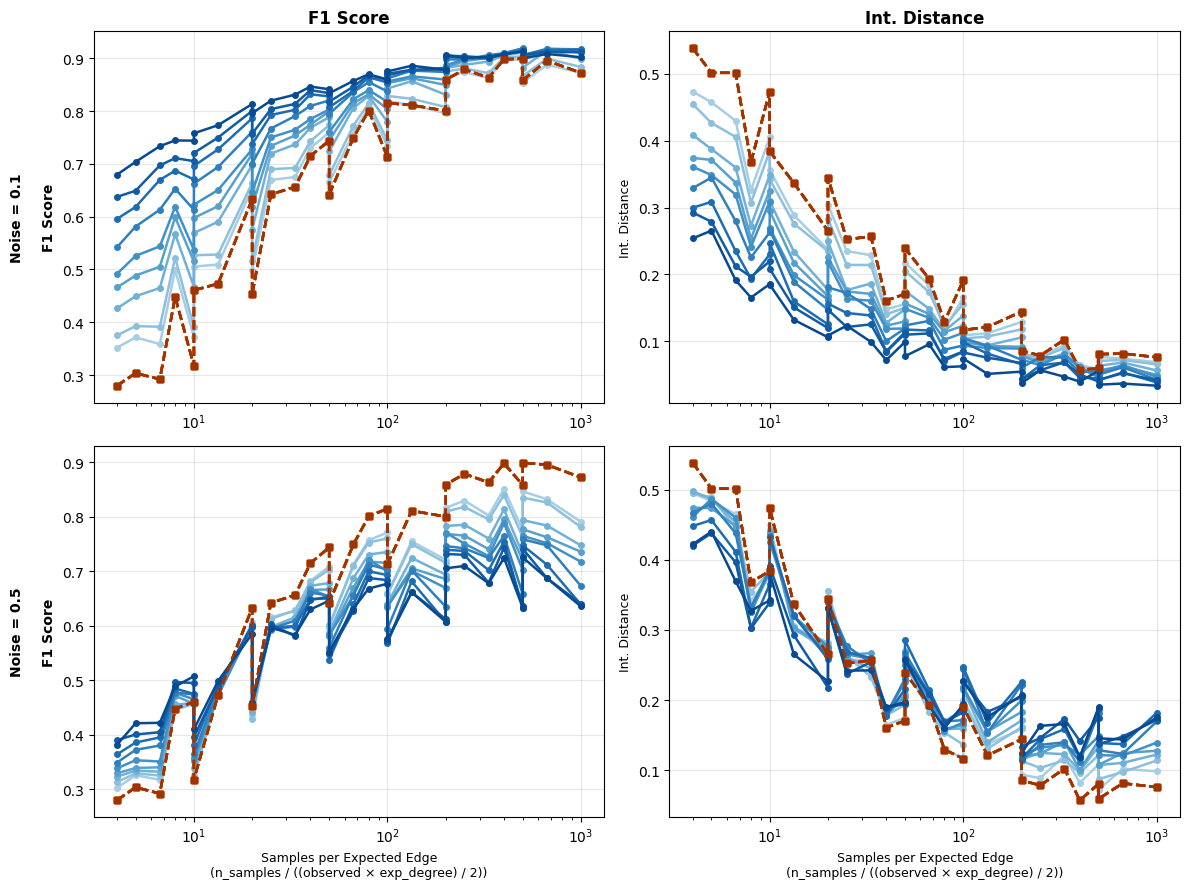

Plotting done.


: 

In [ ]:
import re
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# ── Config ───────────────────────────────────────────────────────────────────
DIR        = "experiment_runs/normal_tar_er2_d10_25_mu01_05"
# Only select noise levels 0.1 and 0.5
NOISE_LEVELS = [0.1, 0.5]   

METRICS = ["f1", "int_dist"]
METRIC_LABELS = {"f1": "F1 Score", "int_dist": "Int. Distance"}

# ── 1. Load & concatenate all CSVs ──────────────────────────────────────────
pattern = os.path.join(DIR, "**", "*.csv")
files   = glob.glob(pattern, recursive=True)
if not files:
    # also try flat
    files = glob.glob(os.path.join(DIR, "*.csv"))

print(f"Found {len(files)} CSV files.")

dfs = []
for fpath in files:
    fname = os.path.basename(fpath)
    # parse false_ratio from filename  e.g. n100_deg2_d10_fr0.1.csv
    match = re.search(r"fr([0-9]+\.?[0-9]*)", fname)
    if match is None:
        continue
    false_ratio = float(match.group(1))

    df_tmp = pd.read_csv(fpath)
    df_tmp["false_ratio"] = false_ratio
    df_tmp["source_file"] = fname
    dfs.append(df_tmp)

if dfs:
    df = pd.concat(dfs, ignore_index=True)
    print(f"Combined shape: {df.shape}")
else:
    print("No data found. Exiting.")
    exit()

# ── 2. Complexity metric ─────────────────────────────────────────────────────
df["complexity_metric"] = df["n_samples"] / ((df["observed"] * df["exp_degree"]) / 2)

# ── 3. Plot ──────────────────────────────────────────────────────────────────
CMAP_WITH    = cm.Blues
CMAP_WITHOUT = cm.Oranges
HUE_COL = "fraction_required"

n_rows = len(NOISE_LEVELS)
n_cols = len(METRICS)

# Create a single grid (2x2 for 2 noise levels and 2 metrics)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows), squeeze=False)

for i, fr in enumerate(NOISE_LEVELS):
    sub = df[np.isclose(df["false_ratio"], fr)]
    if sub.empty:
        print(f"No data for false_ratio={fr}, skipping.")
        continue

    fracs = sorted(sub[HUE_COL].unique()) if HUE_COL in sub.columns else [None]
    n     = len(fracs)
    colors_with    = [CMAP_WITH(0.35 + 0.55 * k / max(n - 1, 1)) for k in range(n)]
    colors_without = [CMAP_WITHOUT(0.35 + 0.55 * k / max(n - 1, 1)) for k in range(n)]

    for j, metric in enumerate(METRICS):
        ax = axes[i, j]
        col_with    = f"{metric}_with_b_mean"
        col_without = f"{metric}_without_b_mean"

        for k, frac in enumerate(fracs):
            if frac is not None:
                grp = sub[np.isclose(sub[HUE_COL], frac)].sort_values("complexity_metric")
            else:
                grp = sub.sort_values("complexity_metric")

            x = grp["complexity_metric"].values

            if col_with in grp.columns:
                ax.plot(x, grp[col_with].values, color=colors_with[k], marker="o",
                        linewidth=1.8, markersize=4,
                        label=f"with_b  frac_req={frac:.1f}" if frac is not None else "with_b")

            if col_without in grp.columns:
                ax.plot(x, grp[col_without].values, color=colors_without[k], marker="s",
                        linewidth=1.8, markersize=4, linestyle="--",
                        label=f"w/o_b   frac_req={frac:.1f}" if frac is not None else "w/o_b")

        # Formatting
        if i == 0:
            ax.set_title(METRIC_LABELS[metric], fontsize=12, fontweight="bold")
        if j == 0:
            ax.set_ylabel(f"Noise = {fr}\n\n{METRIC_LABELS[metric]}", fontsize=10, fontweight="bold")
        else:
            ax.set_ylabel(METRIC_LABELS[metric], fontsize=9)
            
        if i == n_rows - 1:
            ax.set_xlabel("Samples per Expected Edge\n(n_samples / ((observed × exp_degree) / 2))", fontsize=9)
            
        # Keep logarithmic scale for X-axis
        ax.set_xscale('log')
        # Ensure linear scale for Y-axis
        ax.set_yscale('linear')
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Plotting done.")

Found 112 CSV files.
Combined shape: (1008, 15)


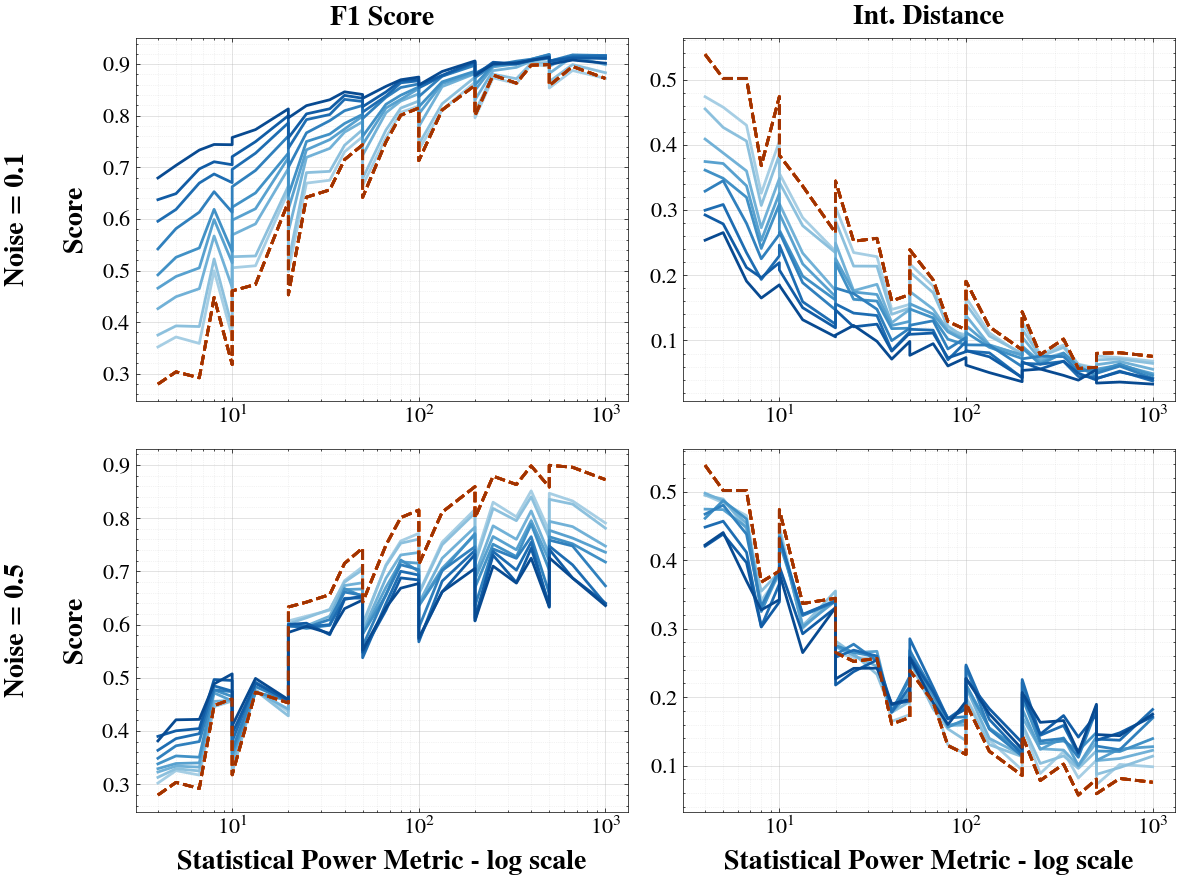

Plotting done.


In [21]:
import re
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import scienceplots

# Apply SciencePlots style
plt.style.use(["science", "no-latex"])

# ── Config ───────────────────────────────────────────────────────────────────
DIRS = [
    "../experiment_runs/noised/normal_tar_er2_d10_25_mu01_05",
]

# Only select noise levels 0.1 and 0.5
NOISE_LEVELS = [0.1, 0.5]   

METRICS = ["f1", "int_dist"]
METRIC_LABELS = {"f1": "F1 Score", "int_dist": "Int. Distance"}

# ── 1. Load & concatenate all CSVs ──────────────────────────────────────────
files = []
for d in DIRS:
    pattern = os.path.join(d, "**", "*.csv")
    d_files = glob.glob(pattern, recursive=True)
    if not d_files:
        d_files = glob.glob(os.path.join(d, "*.csv"))
    files.extend(d_files)

# Remove any duplicates just in case
files = list(set(files))
print(f"Found {len(files)} CSV files.")

dfs = []
for fpath in files:
    fname = os.path.basename(fpath)
    # parse false_ratio from filename e.g. n100_deg2_d10_fr0.1.csv
    match = re.search(r"fr([0-9]+\.?[0-9]*)", fname)
    if match is None:
        continue
    false_ratio = float(match.group(1))

    df_tmp = pd.read_csv(fpath)
    df_tmp["false_ratio"] = false_ratio
    df_tmp["source_file"] = fname
    dfs.append(df_tmp)

if dfs:
    df = pd.concat(dfs, ignore_index=True)
    print(f"Combined shape: {df.shape}")
else:
    print("No data found. Exiting.")
    exit()

# ── 2. Complexity metric ─────────────────────────────────────────────────────
df["complexity_metric"] = df["n_samples"] / ((df["observed"] * df["exp_degree"]) / 2)

# ── 3. Plot ──────────────────────────────────────────────────────────────────
CMAP_WITH    = cm.Blues
CMAP_WITHOUT = cm.Oranges
HUE_COL = "fraction_required"

n_rows = len(NOISE_LEVELS)
n_cols = len(METRICS)

# Keeping original figure scale: (6 * 2, 4.5 * 2) = (12, 9)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows), squeeze=False)

for i, fr in enumerate(NOISE_LEVELS):
    sub = df[np.isclose(df["false_ratio"], fr)]
    if sub.empty:
        print(f"No data for false_ratio={fr}, skipping.")
        continue

    fracs = sorted(sub[HUE_COL].unique()) if HUE_COL in sub.columns else [None]
    n     = len(fracs)
    colors_with    = [CMAP_WITH(0.35 + 0.55 * k / max(n - 1, 1)) for k in range(n)]
    colors_without = [CMAP_WITHOUT(0.35 + 0.55 * k / max(n - 1, 1)) for k in range(n)]

    for j, metric in enumerate(METRICS):
        ax = axes[i, j]
        col_with    = f"{metric}_with_b_mean"
        col_without = f"{metric}_without_b_mean"

        for k, frac in enumerate(fracs):
            if frac is not None:
                grp = sub[np.isclose(sub[HUE_COL], frac)].sort_values("complexity_metric")
            else:
                grp = sub.sort_values("complexity_metric")

            x = grp["complexity_metric"].values

            # Clean lines (no markers), no legend labels
            if col_with in grp.columns:
                ax.plot(x, grp[col_with].values, color=colors_with[k], 
                        linewidth=2.0, linestyle="-")

            if col_without in grp.columns:
                ax.plot(x, grp[col_without].values, color=colors_without[k], 
                        linewidth=2.0, linestyle="--")

        # Formatting
        if i == 0:
            ax.set_title(METRIC_LABELS[metric], fontsize=20, fontweight="bold", pad=10)
        if j == 0:
            ax.set_ylabel(f"Noise = {fr}\n\nScore", fontsize=20, fontweight="bold", labelpad=10)
            
        if i == n_rows - 1:
            ax.set_xlabel("Statistical Power Metric - log scale", 
                          fontsize=20, fontweight="bold", labelpad=8)
            
        ax.tick_params(axis='both', which='major', labelsize=16)
        ax.set_xscale('log')
        ax.set_yscale('linear')
        ax.grid(True, which='major', alpha=0.5, linestyle='-')
        ax.grid(True, which='minor', alpha=0.3, linestyle=':')

# Apply layout constraints
plt.tight_layout(w_pad=1.5, h_pad=1.5)

# Save directly to PDF
plt.savefig("noised_results_lines_no_legend.pdf", bbox_inches="tight")
plt.show()

print("Plotting done.")

Found 112 CSV files.
Combined shape: (1008, 15)


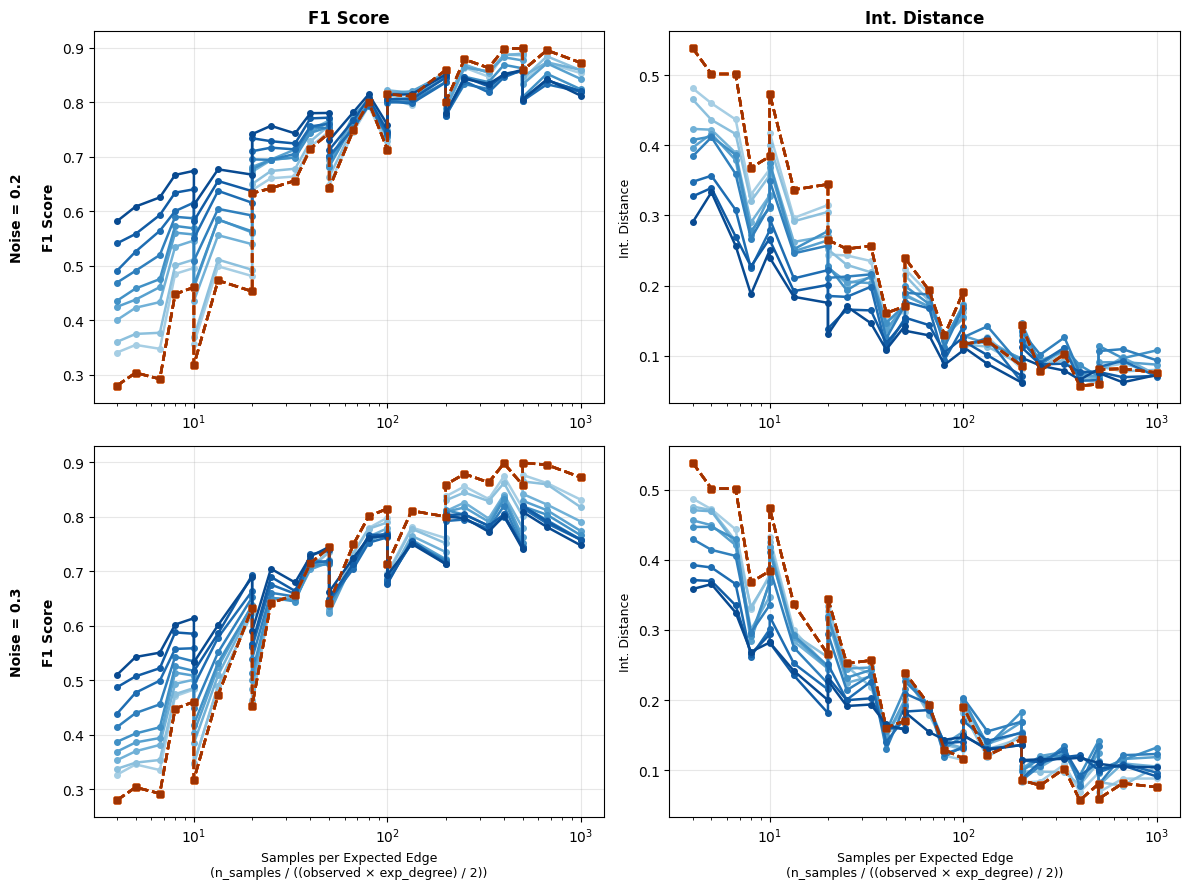

Plotting done.


In [2]:
import re
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# ── Config ───────────────────────────────────────────────────────────────────
DIR        = "../experiment_runs/normal_tar_er2_d10_25_mu01_05"
# Only select noise levels 0.2 and 0.3
NOISE_LEVELS = [0.2, 0.3]   

METRICS = ["f1", "int_dist"]
METRIC_LABELS = {"f1": "F1 Score", "int_dist": "Int. Distance"}

# ── 1. Load & concatenate all CSVs ──────────────────────────────────────────
pattern = os.path.join(DIR, "**", "*.csv")
files   = glob.glob(pattern, recursive=True)
if not files:
    # also try flat
    files = glob.glob(os.path.join(DIR, "*.csv"))

print(f"Found {len(files)} CSV files.")

dfs = []
for fpath in files:
    fname = os.path.basename(fpath)
    # parse false_ratio from filename  e.g. n100_deg2_d10_fr0.1.csv
    match = re.search(r"fr([0-9]+\.?[0-9]*)", fname)
    if match is None:
        continue
    false_ratio = float(match.group(1))

    df_tmp = pd.read_csv(fpath)
    df_tmp["false_ratio"] = false_ratio
    df_tmp["source_file"] = fname
    dfs.append(df_tmp)

if dfs:
    df = pd.concat(dfs, ignore_index=True)
    print(f"Combined shape: {df.shape}")
else:
    print("No data found. Exiting.")
    exit()

# ── 2. Complexity metric ─────────────────────────────────────────────────────
df["complexity_metric"] = df["n_samples"] / ((df["observed"] * df["exp_degree"]) / 2)

# ── 3. Plot ──────────────────────────────────────────────────────────────────
CMAP_WITH    = cm.Blues
CMAP_WITHOUT = cm.Oranges
HUE_COL = "fraction_required"

n_rows = len(NOISE_LEVELS)
n_cols = len(METRICS)

# Create a single grid (2x2 for 2 noise levels and 2 metrics)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows), squeeze=False)

for i, fr in enumerate(NOISE_LEVELS):
    sub = df[np.isclose(df["false_ratio"], fr)]
    if sub.empty:
        print(f"No data for false_ratio={fr}, skipping.")
        continue

    fracs = sorted(sub[HUE_COL].unique()) if HUE_COL in sub.columns else [None]
    n     = len(fracs)
    colors_with    = [CMAP_WITH(0.35 + 0.55 * k / max(n - 1, 1)) for k in range(n)]
    colors_without = [CMAP_WITHOUT(0.35 + 0.55 * k / max(n - 1, 1)) for k in range(n)]

    for j, metric in enumerate(METRICS):
        ax = axes[i, j]
        col_with    = f"{metric}_with_b_mean"
        col_without = f"{metric}_without_b_mean"

        for k, frac in enumerate(fracs):
            if frac is not None:
                grp = sub[np.isclose(sub[HUE_COL], frac)].sort_values("complexity_metric")
            else:
                grp = sub.sort_values("complexity_metric")

            x = grp["complexity_metric"].values

            if col_with in grp.columns:
                ax.plot(x, grp[col_with].values, color=colors_with[k], marker="o",
                        linewidth=1.8, markersize=4,
                        label=f"with_b  frac_req={frac:.1f}" if frac is not None else "with_b")

            if col_without in grp.columns:
                ax.plot(x, grp[col_without].values, color=colors_without[k], marker="s",
                        linewidth=1.8, markersize=4, linestyle="--",
                        label=f"w/o_b   frac_req={frac:.1f}" if frac is not None else "w/o_b")

        # Formatting
        if i == 0:
            ax.set_title(METRIC_LABELS[metric], fontsize=12, fontweight="bold")
        if j == 0:
            ax.set_ylabel(f"Noise = {fr}\n\n{METRIC_LABELS[metric]}", fontsize=10, fontweight="bold")
        else:
            ax.set_ylabel(METRIC_LABELS[metric], fontsize=9)
            
        if i == n_rows - 1:
            ax.set_xlabel("Samples per Expected Edge\n(n_samples / ((observed × exp_degree) / 2))", fontsize=9)
            
        # Keep logarithmic scale for X-axis
        ax.set_xscale('log')
        # Ensure linear scale for Y-axis
        ax.set_yscale('linear')
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Plotting done.")

In [1]:
1+1


2

# Results on synthetic data

## Data loading

Results of applying the PC and b-PC baseline models are in experiment_runs/pc/ (pc_d10_25 for PC results on synthetic graph configurations, eg er2_n100_d10.csv is for ER2 graph, 100 data samples and 10 observed variables, pc_tar_d10_25 for b-pc using local background knowledge strategy). Unlike other result tables, here pc and b-pc are seperated; that means that unlike b-pc or other results where there is a line for each fraction required proportion, pc has just one line per result on a given synthetic graph configurationj

Results of LOAD and b-LOAD models on similar graph configurations can be seen in two areas:
1. experiment_runs/normal/ER2 - ER6: the results of the runs are saved as csv files within a hierarchy of subdirectories: ex: ER2/n100 (number of data samples)/ d10.csv (10 observed nodes)
2. experiment_runs/normal/normal_tar_er5_6_d10_50; here the results of each run are in csv files following similar nomenclature to the pc results with the exception that ER is replaced by deg (eg n100_deg5_d10.csv represents a synthetic graph of 100 data samples, ER5 and number of nodes equal to 10)

concatenate all the results and make similar graphs to what is seen at the end of "Focusing 10 25 variables on target" section:
- for each proportion of exposed background knowledge i want two graphs: one where the f1 scores are compared between pc, b-pc, load and b-load, and another that's identical but for intervention distance. The column names are systematically: observed	exp_degree	n_samples	fraction_forbidden	fraction_required	f1_with_b_mean	f1_with_b_std	f1_without_b_mean	f1_without_b_std	int_dist_with_b_mean	int_dist_with_b_std	int_dist_without_b_mean	int_dist_without_b_std
- the confidence intervals have to be computed based on the std but also given that 1000 iterations were done for each result. Similarly to what has been above:     # Calculate CI consistently (Hardcoded 1000)
    temp_df['confidence_interval_with_b'] = 1.96 * (temp_df['f1_with_b_std'] / np.sqrt(1000))
    temp_df['confidence_interval_without_b'] = 1.96 * (temp_df['f1_without_b_std'] / np.sqrt(1000))

In [1]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── 1. Load PC results (no background knowledge) ─────────────────────────────
pc_files = glob.glob('../experiment_runs/baseline/pc/pc_d10_25/*.csv')
df_pc = pd.concat([pd.read_csv(f) for f in pc_files], ignore_index=True)
print(f"PC:                  {df_pc.shape[0]:>5} rows")

# ── 2. Load b-PC results (local background knowledge sampling) ────────────────
bpc_files = glob.glob('../experiment_runs/baseline/pc/pc_tar_d10_25/*.csv')
df_bpc = pd.concat([pd.read_csv(f) for f in bpc_files], ignore_index=True)
print(f"b-PC (local):        {df_bpc.shape[0]:>5} rows")

# ── 3. Load LOAD results — ER2–ER6 subdirectory hierarchy ────────────────────
load_er_files = glob.glob('../experiment_runs/normal/ER*/**/*.csv', recursive=True)
df_load_er = pd.concat([pd.read_csv(f) for f in load_er_files], ignore_index=True)
print(f"LOAD (ER hierarchy): {df_load_er.shape[0]:>5} rows")

# ── 4. Load extra LOAD results — ER5/ER6, d10–50 ─────────────────────────────
load_extra_files = glob.glob('../experiment_runs/normal/normal_tar_er5_6_d10_50/*.csv')
df_load_extra = pd.concat([pd.read_csv(f) for f in load_extra_files], ignore_index=True)
print(f"LOAD (ER5/6 extra):  {df_load_extra.shape[0]:>5} rows")

# ── 5. Combine LOAD sources, drop exact duplicates ───────────────────────────
df_load = pd.concat([df_load_er, df_load_extra], ignore_index=True)
key_cols = ['observed', 'exp_degree', 'n_samples', 'fraction_required', 'fraction_forbidden']
df_load = df_load.drop_duplicates(subset=key_cols)
print(f"LOAD (combined):     {df_load.shape[0]:>5} rows")
print()
print("b-PC fraction_required values:", sorted(df_bpc['fraction_required'].unique()))
print("LOAD fraction_required values:", sorted(df_load['fraction_required'].unique()))
# ── 6. Load b-LOAD (global sampling) results ─────────────────────────────────
bload_global_files = (
    glob.glob('../experiment_runs/normal/normal_all_er2_4_d10_25/*.csv') +
    glob.glob('../experiment_runs/normal/normal_all_er2_6_d50/*.csv') +
    glob.glob('../experiment_runs/normal/normal_all_er2_6_d50_bis/*.csv')
)
df_bload_global = pd.concat([pd.read_csv(f) for f in bload_global_files], ignore_index=True)
key_cols = ['observed', 'exp_degree', 'n_samples', 'fraction_required', 'fraction_forbidden']
df_bload_global = df_bload_global.drop_duplicates(subset=key_cols)
print(f"b-LOAD (global):     {df_bload_global.shape[0]:>5} rows")
print("b-LOAD (global) fraction_required values:", sorted(df_bload_global['fraction_required'].unique()))
print("b-LOAD (global) observed values:         ", sorted(df_bload_global['observed'].unique()))


PC:                    140 rows
b-PC (local):         1260 rows
LOAD (ER hierarchy):   815 rows
LOAD (ER5/6 extra):    498 rows
LOAD (combined):      1254 rows

b-PC fraction_required values: [np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9)]
LOAD fraction_required values: [np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9)]
b-LOAD (global):      1023 rows
b-LOAD (global) fraction_required values: [np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9)]
b-LOAD (global) observed values:          [np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(50)]


In [2]:
# ═══════════════════════════════════════════════════════════════════════════════
#  Load new results and append to existing dataframes
#  Also creates the new df_bpc_global dataframe.
# ═══════════════════════════════════════════════════════════════════════════════
import re, os, glob
import numpy as np
import pandas as pd
from collections import defaultdict

N_PER_ITER = 100   # iterations per job file in 100-iter folders
BASE = '../experiment_runs'

# ── Aggregation helpers (exact parallel variance formula) ─────────────────────
def combine_stats(job_results):
    """job_results: list of (n, mean, var) tuples. Returns (global_mean, global_std)."""
    N = sum(n for n, _, _ in job_results)
    global_mean = sum(n * m for n, m, _ in job_results) / N
    combined_var = (
        sum((n - 1) * v + n * (m - global_mean) ** 2 for n, m, v in job_results)
        / (N - 1)
    )
    return global_mean, np.sqrt(combined_var)

def load_iter_folder(folder, stat_col_pairs, n_per_iter=N_PER_ITER):
    """
    Load a 100-iter folder.  Groups files by base config (strips _iter{n}),
    reads every iter file once, then combines stats with combine_stats().
    stat_col_pairs: list of (mean_col, std_col) tuples to aggregate.
    Returns one aggregated row per config.
    """
    files = sorted(glob.glob(os.path.join(folder, '*.csv')))
    if not files:
        print(f"  WARNING: no files in {folder}")
        return pd.DataFrame()

    groups = defaultdict(list)
    for f in files:
        base = re.sub(r'_iter\d+\.csv$', '', os.path.basename(f))
        groups[base].append(f)

    rows = []
    for base, flist in sorted(groups.items()):
        iter_dfs = [pd.read_csv(f) for f in sorted(flist)]
        row = iter_dfs[0].iloc[0].to_dict()          # metadata from first iter
        for mean_col, std_col in stat_col_pairs:
            job_results = [
                (n_per_iter, df[mean_col].iloc[0], df[std_col].iloc[0] ** 2)
                for df in iter_dfs
            ]
            row[mean_col], row[std_col] = combine_stats(job_results)
        rows.append(row)

    n_iters = max(len(v) for v in groups.values())
    print(f"    {n_iters} iters × {len(rows)} configs  ← {os.path.basename(folder)}")
    return pd.DataFrame(rows)

# Stat column pairs per df type
PC_STATS   = [('f1_mean', 'f1_std'), ('int_dist_mean', 'int_dist_std')]
LOAD_STATS = [
    ('f1_with_b_mean',        'f1_with_b_std'),
    ('f1_without_b_mean',     'f1_without_b_std'),
    ('int_dist_with_b_mean',  'int_dist_with_b_std'),
    ('int_dist_without_b_mean','int_dist_without_b_std'),
]
KEY_PC   = ['observed', 'exp_degree', 'n_samples']
KEY_BPC  = ['observed', 'exp_degree', 'n_samples', 'fraction_required']
KEY_LOAD = ['observed', 'exp_degree', 'n_samples', 'fraction_required', 'fraction_forbidden']

print("=" * 70)

# ── 1. df_pc — add d=50 and d=100 (standard folders) ─────────────────────────
print("\n[1] df_pc  — adding d=50 and d=100")
_new_pc = pd.concat([
    pd.concat([pd.read_csv(f) for f in glob.glob(f'{BASE}/baseline/pc/pc_d50/*.csv')],  ignore_index=True),
    pd.concat([pd.read_csv(f) for f in glob.glob(f'{BASE}/baseline/pc/pc_d100/*.csv')], ignore_index=True),
], ignore_index=True)
print(f"    {len(_new_pc)} new rows")
df_pc = pd.concat([df_pc, _new_pc], ignore_index=True).drop_duplicates(subset=KEY_PC)
print(f"  → df_pc: {len(df_pc)} rows  |  observed: {sorted(df_pc['observed'].unique())}")

# ── 2. df_bpc — add d=50 (ER2-3, ER4-6) and d=100 (100-iter folders) ────────
print("\n[2] df_bpc  — adding d=50 and d=100")
_bpc_iters = [
    load_iter_folder(f'{BASE}/baseline/pc/pc_tar_er2_3_d50_prod', PC_STATS),
    load_iter_folder(f'{BASE}/baseline/pc/pc_tar_er4_6_d50_prod', PC_STATS),
    load_iter_folder(f'{BASE}/baseline/pc/pc_tar_er2_6_d100_prod', PC_STATS),
]
df_bpc = pd.concat([df_bpc] + _bpc_iters, ignore_index=True).drop_duplicates(subset=KEY_BPC)
print(f"  → df_bpc: {len(df_bpc)} rows  |  observed: {sorted(df_bpc['observed'].unique())}")

# ── 3. df_load — add d=50 (standard) + d=100 + missing ER5-6 d20-25 (100-iter)
print("\n[3] df_load  — adding d=50 (std) + d=100 + missing ER5/6 d20-25")
_new_load_std = pd.concat([pd.read_csv(f) for f in glob.glob(
    f'{BASE}/normal/normal_tar_er2_6_d50/*.csv')], ignore_index=True)
_load_iters = [
    load_iter_folder(f'{BASE}/normal/normal_tar_er2_6_d100_prod', LOAD_STATS),
    load_iter_folder(f'{BASE}/normal/tar_er5_6_d20_25_missing',   LOAD_STATS),
]
df_load = pd.concat([df_load, _new_load_std] + _load_iters, ignore_index=True).drop_duplicates(subset=KEY_LOAD)
print(f"  → df_load: {len(df_load)} rows  |  observed: {sorted(df_load['observed'].unique())}")

# ── 4. df_bload_global — add missing d20-25 (100-iter) + d=100 + ER5-6 d10-25 (std)
print("\n[4] df_bload_global  — adding missing d20-25 + d=100 + ER5-6 d10-25")
_bglob_iters = [
    load_iter_folder(f'{BASE}/normal/all_er2_4_d20_25_missing', LOAD_STATS),
]
_new_bglob_std = pd.concat([
    pd.concat([pd.read_csv(f) for f in glob.glob(f'{BASE}/normal/normal_all_er2_3_d100/*.csv')],   ignore_index=True),
    pd.concat([pd.read_csv(f) for f in glob.glob(f'{BASE}/normal/normal_all_er5_6_d10_25/*.csv')], ignore_index=True),
], ignore_index=True)
df_bload_global = pd.concat([df_bload_global, _new_bglob_std] + _bglob_iters, ignore_index=True).drop_duplicates(subset=KEY_LOAD)
print(f"  → df_bload_global: {len(df_bload_global)} rows  |  observed: {sorted(df_bload_global['observed'].unique())}")

# ── 5. df_bpc_global — NEW: global-BK PC baseline ────────────────────────────
print("\n[5] df_bpc_global  — NEW (global BK for PC): d=10-25 (std) + d=50,100 (100-iter)")
_new_bpcg_std = pd.concat([pd.read_csv(f) for f in glob.glob(
    f'{BASE}/baseline/pc/pc_all_d10_25/*.csv')], ignore_index=True)
_bpcg_iters = [
    load_iter_folder(f'{BASE}/baseline/pc/pc_all_er2_6_d50_prod',  PC_STATS),
    load_iter_folder(f'{BASE}/baseline/pc/pc_all_er2_6_d100_prod', PC_STATS),
]
df_bpc_global = pd.concat([_new_bpcg_std] + _bpcg_iters, ignore_index=True).drop_duplicates(subset=KEY_BPC)
print(f"  → df_bpc_global: {len(df_bpc_global)} rows  |  observed: {sorted(df_bpc_global['observed'].unique())}")

print("\n" + "=" * 70)
print("All dataframes updated.")



[1] df_pc  — adding d=50 and d=100
    49 new rows
  → df_pc: 189 rows  |  observed: [np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(50), np.int64(100)]

[2] df_bpc  — adding d=50 and d=100
    10 iters × 126 configs  ← pc_tar_er2_3_d50_prod
    10 iters × 189 configs  ← pc_tar_er4_6_d50_prod
    10 iters × 126 configs  ← pc_tar_er2_6_d100_prod
  → df_bpc: 1701 rows  |  observed: [np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(50), np.int64(100)]

[3] df_load  — adding d=50 (std) + d=100 + missing ER5/6 d20-25
    10 iters × 126 configs  ← normal_tar_er2_6_d100_prod
    10 iters × 36 configs  ← tar_er5_6_d20_25_missing
  → df_load: 1701 rows  |  observed: [np.float64(10.0), np.float64(15.0), np.float64(20.0), np.float64(25.0), np.float64(50.0), np.float64(100.0)]

[4] df_bload_global  — adding missing d20-25 + d=100 + ER5-6 d10-25
    10 iters × 54 configs  ← all_er2_4_d20_25_missing
  → df_bload_global: 1701 rows  |  observed: [np.float64(10.0), np

## Data processing: adding complexity metric and CIs

In [3]:
# ── Complexity metric: samples per expected edge ──────────────────────────────
for df in [df_pc, df_bpc, df_load, df_bload_global]:
    df['complexity_metric'] = df['n_samples'] / ((df['observed'] * df['exp_degree']) / 2)

# ── 95% confidence intervals (1000 iterations assumed throughout) ─────────────
N_ITER = 1000

df_pc['ci_f1']       = 1.96 * df_pc['f1_std']       / np.sqrt(N_ITER)
df_pc['ci_int_dist'] = 1.96 * df_pc['int_dist_std']  / np.sqrt(N_ITER)

df_bpc['ci_f1']       = 1.96 * df_bpc['f1_std']       / np.sqrt(N_ITER)
df_bpc['ci_int_dist'] = 1.96 * df_bpc['int_dist_std'] / np.sqrt(N_ITER)

df_load['ci_f1_with_b']          = 1.96 * df_load['f1_with_b_std']          / np.sqrt(N_ITER)
df_load['ci_f1_without_b']       = 1.96 * df_load['f1_without_b_std']       / np.sqrt(N_ITER)
df_load['ci_int_dist_with_b']    = 1.96 * df_load['int_dist_with_b_std']    / np.sqrt(N_ITER)
df_load['ci_int_dist_without_b'] = 1.96 * df_load['int_dist_without_b_std'] / np.sqrt(N_ITER)

# ── LOAD without-BK baseline: one row per (observed, exp_degree, n_samples) ──
# f1_without_b_mean is identical across fraction_required for the same config,
# so we just keep the first occurrence per config.
_load_no_bk_cols = [
    'observed', 'exp_degree', 'n_samples', 'complexity_metric',
    'f1_without_b_mean',    'ci_f1_without_b',
    'int_dist_without_b_mean', 'ci_int_dist_without_b',
]
df_load_no_bk = (
    df_load
    .drop_duplicates(subset=['observed', 'exp_degree', 'n_samples'])
    [_load_no_bk_cols]
    .copy()
)


df_bload_global['ci_f1_with_b']       = 1.96 * df_bload_global['f1_with_b_std']       / np.sqrt(N_ITER)
df_bload_global['ci_int_dist_with_b'] = 1.96 * df_bload_global['int_dist_with_b_std'] / np.sqrt(N_ITER)

print("b-LOAD (global) complexity range:",
      f"{df_bload_global['complexity_metric'].min():.1f} – {df_bload_global['complexity_metric'].max():.1f}")
print("Complexity metric range (PC):",
      f"{df_pc['complexity_metric'].min():.1f} – {df_pc['complexity_metric'].max():.1f}")
print("Complexity metric range (LOAD):",
      f"{df_load['complexity_metric'].min():.1f} – {df_load['complexity_metric'].max():.1f}")

b-LOAD (global) complexity range: 0.7 – 1000.0
Complexity metric range (PC): 0.7 – 1000.0
Complexity metric range (LOAD): 0.7 – 1000.0


In [4]:
# ── df_bpc_global: complexity metric + 95 % CIs ──────────────────────────────
df_bpc_global['complexity_metric'] = (
    df_bpc_global['n_samples'] / ((df_bpc_global['observed'] * df_bpc_global['exp_degree']) / 2)
)
df_bpc_global['ci_f1']       = 1.96 * df_bpc_global['f1_std']       / np.sqrt(N_ITER)
df_bpc_global['ci_int_dist'] = 1.96 * df_bpc_global['int_dist_std'] / np.sqrt(N_ITER)

# Also refresh df_load_no_bk after the data expansion
_load_no_bk_cols = [
    'observed', 'exp_degree', 'n_samples', 'complexity_metric',
    'f1_without_b_mean',       'ci_f1_without_b',
    'int_dist_without_b_mean', 'ci_int_dist_without_b',
]
df_load_no_bk = (
    df_load
    .drop_duplicates(subset=['observed', 'exp_degree', 'n_samples'])
    [_load_no_bk_cols]
    .copy()
)

print("df_bpc_global complexity range:",
      f"{df_bpc_global['complexity_metric'].min():.1f} – {df_bpc_global['complexity_metric'].max():.1f}")
print("Rows per observed (df_bpc_global):")
print(df_bpc_global.groupby('observed').size().to_string())


df_bpc_global complexity range: 0.7 – 1000.0
Rows per observed (df_bpc_global):
observed
10     315
15     315
20     315
25     315
50     315
100    126


## Table format aggregate results for different Pi regimes

### Triple regime analysis: Low, Med, High

In [38]:
import pandas as pd
import numpy as np

def bin_complexity(pi):
    """Segment the complexity metric (Pi) into Low, Medium, High regimes."""
    if pi < 10:
        return 'Low'
    elif 10 <= pi < 100:
        return 'Medium'
    else:
        return 'High'

def process_methods(df_pc, df_bpc, df_load, df_bload_global):
    """
    Process the dataframes to calculate average F1 and Intervention Distance 
    across frac_reqs for each method and complexity regime.
    """
    records = []
    regimes = ['Low', 'Medium', 'High']
    
    # 1. Helper function to extract and format data for a specific method
    def extract_method_data(df, method_name, f1_col, int_dist_col, frac_req_col=None):
        temp_df = df.copy()
        temp_df['regime'] = temp_df['complexity_metric'].apply(bin_complexity)
        
        row_data = {'Method': method_name}
        
        for regime in regimes:
            regime_df = temp_df[temp_df['regime'] == regime]
            
            if regime_df.empty:
                f1_val = np.nan
                int_dist_val = np.nan
            else:
                # Direct mean across the regime subset
                # (For b-methods, this averages across all fraction_required variations in that regime)
                f1_val = regime_df[f1_col].mean()
                int_dist_val = regime_df[int_dist_col].mean()
            
            row_data[f'{regime} F1'] = f1_val
            row_data[f'{regime} Int. Dist.'] = int_dist_val
            
        return row_data

    # 2. Extract data for each of the 5 methods
    
    # --- PC Baseline ---
    records.append(extract_method_data(
        df_pc, 'PC', 
        f1_col='f1_mean', int_dist_col='int_dist_mean'
    ))
    
    # --- b-PC (local) ---
    records.append(extract_method_data(
        df_bpc, 'b-PC (local)', 
        f1_col='f1_mean', int_dist_col='int_dist_mean', frac_req_col='fraction_required'
    ))
    
    # --- LOAD Baseline (Extracted from df_load) ---
    # Drop duplicates so we don't over-weight the mean by the redundant fraction_required rows
    df_load_baseline = df_load.drop_duplicates(subset=['observed', 'exp_degree', 'n_samples'])
    records.append(extract_method_data(
        df_load_baseline, 'LOAD', 
        f1_col='f1_without_b_mean', int_dist_col='int_dist_without_b_mean'
    ))
    
    # --- b-LOAD (local) ---
    records.append(extract_method_data(
        df_load, 'b-LOAD (local)', 
        f1_col='f1_with_b_mean', int_dist_col='int_dist_with_b_mean', frac_req_col='fraction_required'
    ))
    
    # --- b-LOAD (global) ---
    records.append(extract_method_data(
        df_bload_global, 'b-LOAD (global)', 
        f1_col='f1_with_b_mean', int_dist_col='int_dist_with_b_mean', frac_req_col='fraction_required'
    ))
    
    # 3. Create the summary DataFrame
    summary_df = pd.DataFrame(records)
    
    # 4. Determine the best model for each metric in each regime
    best_row = {'Method': 'Best Model'}
    
    for regime in regimes:
        f1_col = f'{regime} F1'
        int_dist_col = f'{regime} Int. Dist.'
        
        # Best F1 (Maximum)
        if summary_df[f1_col].notna().any():
            best_f1_idx = summary_df[f1_col].idxmax()
            best_row[f1_col] = summary_df.loc[best_f1_idx, 'Method']
        else:
            best_row[f1_col] = None
            
        # Best Intervention Distance (Minimum)
        if summary_df[int_dist_col].notna().any():
            best_int_idx = summary_df[int_dist_col].idxmin()
            best_row[int_dist_col] = summary_df.loc[best_int_idx, 'Method']
        else:
            best_row[int_dist_col] = None
            
    # Append the best model row
    best_df = pd.DataFrame([best_row])
    final_df = pd.concat([summary_df, best_df], ignore_index=True)
    
    # 5. Format and round
    numeric_cols = final_df.select_dtypes(include=[np.number]).columns
    final_df[numeric_cols] = final_df[numeric_cols].round(4)
    
    return final_df

# Example execution assuming DataFrames are in memory:
# final_table = process_methods(df_pc, df_bpc, df_load, df_bload_global)
# print(final_table.to_markdown(index=False))

In [4]:
# Example execution assuming DataFrames are in memory:
final_table = process_methods(df_pc, df_bpc, df_load, df_bload_global)
final_table

,Method,Low F1,Low Int. Dist.,Medium F1,Medium Int. Dist.,High F1,High Int. Dist.
0,PC,0.055696,2.474619,0.149583,1.927233,0.292493,1.343525
1,b-PC (local),0.246091,1.973227,0.286585,1.419911,0.38018,0.968519
2,LOAD,0.12481,2.986292,0.292051,1.755143,0.482713,1.030792
3,b-LOAD (local),0.327599,2.048424,0.473079,1.325367,0.63357,0.710914
4,b-LOAD (global),0.412303,0.881293,0.578601,0.595264,0.722786,0.367487
5,Best Model,b-LOAD (global),b-LOAD (global),b-LOAD (global),b-LOAD (global),b-LOAD (global),b-LOAD (global)


In [39]:
# Example execution assuming DataFrames are in memory:
final_table = process_methods(df_pc, df_bpc, df_load, df_bload_global)
final_table

,Method,Low F1,Low Int. Dist.,Medium F1,Medium Int. Dist.,High F1,High Int. Dist.
0,PC,0.067109,2.89936,0.167005,2.151446,0.313298,1.279315
1,b-PC (local),0.253753,2.414937,0.295702,1.584412,0.400201,0.922551
2,LOAD,0.163289,2.506879,0.335179,1.786434,0.494151,1.101394
3,b-LOAD (local),0.347423,2.194576,0.49164,1.496646,0.627551,0.815088
4,b-LOAD (global),0.362143,2.363387,0.502684,1.583263,0.637026,0.864015
5,Best Model,b-LOAD (global),b-LOAD (local),b-LOAD (global),b-LOAD (local),b-LOAD (global),b-LOAD (local)


In [5]:
# ── Triple-regime summary table — 6 methods (incl. b-PC global) ───────────────
import pandas as pd
import numpy as np

def bin_complexity_3(pi):
    if pi < 10:   return 'Low'
    if pi < 100:  return 'Medium'
    return 'High'

def process_methods_v2(df_pc, df_bpc, df_bpc_global, df_load, df_bload_global):
    """6-method summary: PC / b-PC (local) / b-PC (global) / LOAD / b-LOAD (local) / b-LOAD (global)."""
    regimes = ['Low', 'Medium', 'High']

    def extract(df, name, f1_col, id_col):
        tmp = df.copy()
        tmp['regime'] = tmp['complexity_metric'].apply(bin_complexity_3)
        row = {'Method': name}
        for r in regimes:
            sub = tmp[tmp['regime'] == r]
            row[f'{r} F1']         = sub[f1_col].mean()   if not sub.empty else np.nan
            row[f'{r} Int. Dist.'] = sub[id_col].mean()   if not sub.empty else np.nan
        return row

    df_load_base = df_load.drop_duplicates(subset=['observed', 'exp_degree', 'n_samples'])

    records = [
        extract(df_pc,         'PC',             'f1_mean',           'int_dist_mean'),
        extract(df_bpc,        'b-PC (local)',   'f1_mean',           'int_dist_mean'),
        extract(df_bpc_global, 'b-PC (global)',  'f1_mean',           'int_dist_mean'),
        extract(df_load_base,  'LOAD',           'f1_without_b_mean', 'int_dist_without_b_mean'),
        extract(df_load,       'b-LOAD (local)', 'f1_with_b_mean',    'int_dist_with_b_mean'),
        extract(df_bload_global,'b-LOAD (global)','f1_with_b_mean',   'int_dist_with_b_mean'),
    ]
    summary = pd.DataFrame(records)

    best_row = {'Method': 'Best Model'}
    for r in regimes:
        fc, ic = f'{r} F1', f'{r} Int. Dist.'
        best_row[fc] = summary.loc[summary[fc].idxmax(), 'Method'] if summary[fc].notna().any() else None
        best_row[ic] = summary.loc[summary[ic].idxmin(), 'Method'] if summary[ic].notna().any() else None

    final = pd.concat([summary, pd.DataFrame([best_row])], ignore_index=True)
    final[final.select_dtypes(include=[np.number]).columns] = (
        final.select_dtypes(include=[np.number]).round(4)
    )
    return final

final_table_v2 = process_methods_v2(df_pc, df_bpc, df_bpc_global, df_load, df_bload_global)
final_table_v2


,Method,Low F1,Low Int. Dist.,Medium F1,Medium Int. Dist.,High F1,High Int. Dist.
0,PC,0.067109,2.89936,0.167005,2.151446,0.313298,1.279315
1,b-PC (local),0.253753,2.414937,0.295702,1.584412,0.400201,0.922551
2,b-PC (global),0.190602,2.141464,0.250516,1.415058,0.379548,0.834321
3,LOAD,0.163289,2.506879,0.335179,1.786434,0.494151,1.101394
4,b-LOAD (local),0.347423,2.194576,0.49164,1.496646,0.627551,0.815088
5,b-LOAD (global),0.362143,2.363387,0.502684,1.583263,0.637026,0.864015
6,Best Model,b-LOAD (global),b-PC (global),b-LOAD (global),b-PC (global),b-LOAD (global),b-LOAD (local)


In [13]:
import pandas as pd
import numpy as np

def bin_complexity_3(pi):
    if pi < 10:   return 'Low'
    if pi < 100:  return 'Medium'
    return 'High'

def process_methods_v2(df_pc, df_bpc, df_bpc_global, df_load, df_bload_global):
    """
    Summary table showing base PC and LOAD, plus 4 b-methods split into 
    low, med, and high fraction_required levels.
    """
    regimes = ['Low', 'Medium', 'High']

    def extract(df, name, f1_col, id_col):
        tmp = df.copy()
        tmp['regime'] = tmp['complexity_metric'].apply(bin_complexity_3)
        row = {'Method': name}
        for r in regimes:
            sub = tmp[tmp['regime'] == r]
            row[f'{r} F1']         = sub[f1_col].mean()   if not sub.empty else np.nan
            row[f'{r} Int. Dist.'] = sub[id_col].mean()   if not sub.empty else np.nan
        return row

    # Extract base LOAD which is independent of fraction_required
    df_load_base = df_load.drop_duplicates(subset=['observed', 'exp_degree', 'n_samples'])

    # Start with base methods (no fraction splits)
    records = [
        extract(df_pc,        'PC',   'f1_mean',           'int_dist_mean'),
        extract(df_load_base, 'LOAD', 'f1_without_b_mean', 'int_dist_without_b_mean'),
    ]

    # Define the 4 methods that have a fraction_required parameter
    b_methods = [
        (df_bpc,          'b-PC (local)',   'f1_mean',        'int_dist_mean'),
        (df_bpc_global,   'b-PC (global)',  'f1_mean',        'int_dist_mean'),
        (df_load,         'b-LOAD (local)', 'f1_with_b_mean', 'int_dist_with_b_mean'),
        (df_bload_global, 'b-LOAD (global)','f1_with_b_mean', 'int_dist_with_b_mean'),
    ]

    # Safe intervals to bypass potential floating-point inaccuracies
    frac_ranges = {
        'low':  (0.09, 0.31), # Covers 0.1 to 0.3
        'med':  (0.39, 0.61), # Covers 0.4 to 0.6
        'high': (0.69, 0.91)  # Covers 0.7 to 0.9
    }

    # Extract the 3 sub-levels for each b-method
    for df, base_name, f1_col, id_col in b_methods:
        for level_name, (min_val, max_val) in frac_ranges.items():
            mask = (df['fraction_required'] >= min_val) & (df['fraction_required'] <= max_val)
            sub_df = df[mask]
            
            # Name will look like "b-PC (local)_low"
            new_name = f"{base_name}_{level_name}"
            records.append(extract(sub_df, new_name, f1_col, id_col))

    summary = pd.DataFrame(records)

    # Determine Best Model
    best_row = {'Method': 'Best Model'}
    for r in regimes:
        fc, ic = f'{r} F1', f'{r} Int. Dist.'
        best_row[fc] = summary.loc[summary[fc].idxmax(), 'Method'] if summary[fc].notna().any() else None
        best_row[ic] = summary.loc[summary[ic].idxmin(), 'Method'] if summary[ic].notna().any() else None

    # Concatenate and format
    final = pd.concat([summary, pd.DataFrame([best_row])], ignore_index=True)
    final[final.select_dtypes(include=[np.number]).columns] = (
        final.select_dtypes(include=[np.number]).round(4)
    )
    
    return final

In [14]:
final_table_v3 = process_methods_v2(df_pc, df_bpc, df_bpc_global, df_load, df_bload_global)
final_table_v3

,Method,Low F1,Low Int. Dist.,Medium F1,Medium Int. Dist.,High F1,High Int. Dist.
0,PC,0.067109,2.89936,0.167005,2.151446,0.313298,1.279315
1,LOAD,0.163289,2.506879,0.335179,1.786434,0.494151,1.101394
2,b-PC (local)_low,0.132429,2.726751,0.222221,1.852338,0.353507,1.070343
3,b-PC (local)_med,0.240263,2.419636,0.290078,1.581375,0.396866,0.912024
4,b-PC (local)_high,0.388568,2.098425,0.374806,1.319524,0.450231,0.785287
5,b-PC (global)_low,0.106837,2.629736,0.193562,1.778222,0.332582,1.048228
6,b-PC (global)_med,0.182868,2.074631,0.241791,1.366916,0.370694,0.809632
7,b-PC (global)_high,0.2821,1.720025,0.316196,1.100035,0.435369,0.645101
8,b-LOAD (local)_low,0.222683,2.422889,0.386235,1.699104,0.53837,0.988245
9,b-LOAD (local)_med,0.32213,2.271742,0.468787,1.566049,0.609726,0.857112


### Double regime analysis: Low, High

In [7]:
import pandas as pd
import numpy as np

def bin_complexity(pi):
    """Segment the complexity metric (Pi) into Low and High regimes."""
    # Using 50 as the split threshold. Adjust this value as needed for your specific analysis.
    if pi < 50:
        return 'Low'
    else:
        return 'High'

def process_methods_two_regimes(df_pc, df_bpc, df_load, df_bload_global):
    """
    Process the dataframes to calculate average F1 and Intervention Distance 
    across frac_reqs for each method in Low and High complexity regimes.
    """
    records = []
    regimes = ['Low', 'High']
    
    # 1. Helper function to extract and format data for a specific method
    def extract_method_data(df, method_name, f1_col, int_dist_col, frac_req_col=None):
        temp_df = df.copy()
        temp_df['regime'] = temp_df['complexity_metric'].apply(bin_complexity)
        
        row_data = {'Method': method_name}
        
        for regime in regimes:
            regime_df = temp_df[temp_df['regime'] == regime]
            
            if regime_df.empty:
                f1_val = np.nan
                int_dist_val = np.nan
            else:
                # Direct mean across the regime subset
                f1_val = regime_df[f1_col].mean()
                int_dist_val = regime_df[int_dist_col].mean()
            
            row_data[f'{regime} F1'] = f1_val
            row_data[f'{regime} Int. Dist.'] = int_dist_val
            
        return row_data

    # 2. Extract data for each of the 5 methods
    
    # --- PC Baseline ---
    records.append(extract_method_data(
        df_pc, 'PC', 
        f1_col='f1_mean', int_dist_col='int_dist_mean'
    ))
    
    # --- b-PC (local) ---
    records.append(extract_method_data(
        df_bpc, 'b-PC (local)', 
        f1_col='f1_mean', int_dist_col='int_dist_mean', frac_req_col='fraction_required'
    ))
    
    # --- LOAD Baseline (Extracted from df_load) ---
    # Drop duplicates so we don't over-weight the mean by the redundant fraction_required rows
    df_load_baseline = df_load.drop_duplicates(subset=['observed', 'exp_degree', 'n_samples'])
    records.append(extract_method_data(
        df_load_baseline, 'LOAD', 
        f1_col='f1_without_b_mean', int_dist_col='int_dist_without_b_mean'
    ))
    
    # --- b-LOAD (local) ---
    records.append(extract_method_data(
        df_load, 'b-LOAD (local)', 
        f1_col='f1_with_b_mean', int_dist_col='int_dist_with_b_mean', frac_req_col='fraction_required'
    ))
    
    # --- b-LOAD (global) ---
    records.append(extract_method_data(
        df_bload_global, 'b-LOAD (global)', 
        f1_col='f1_with_b_mean', int_dist_col='int_dist_with_b_mean', frac_req_col='fraction_required'
    ))
    
    # 3. Create the summary DataFrame
    summary_df = pd.DataFrame(records)
    
    # 4. Determine the best model for each metric in each regime
    best_row = {'Method': 'Best Model'}
    
    for regime in regimes:
        f1_col = f'{regime} F1'
        int_dist_col = f'{regime} Int. Dist.'
        
        # Best F1 (Maximum)
        if summary_df[f1_col].notna().any():
            best_f1_idx = summary_df[f1_col].idxmax()
            best_row[f1_col] = summary_df.loc[best_f1_idx, 'Method']
        else:
            best_row[f1_col] = None
            
        # Best Intervention Distance (Minimum)
        if summary_df[int_dist_col].notna().any():
            best_int_idx = summary_df[int_dist_col].idxmin()
            best_row[int_dist_col] = summary_df.loc[best_int_idx, 'Method']
        else:
            best_row[int_dist_col] = None
            
    # Append the best model row
    best_df = pd.DataFrame([best_row])
    final_df = pd.concat([summary_df, best_df], ignore_index=True)
    
    # 5. Format and round
    numeric_cols = final_df.select_dtypes(include=[np.number]).columns
    final_df[numeric_cols] = final_df[numeric_cols].round(4)
    
    return final_df

# Example execution:
# final_table = process_methods_two_regimes(df_pc, df_bpc, df_load, df_bload_global)
# print(final_table.to_markdown(index=False))

In [6]:
final_table = process_methods_two_regimes(df_pc, df_bpc, df_load, df_bload_global)
final_table


,Method,Low F1,Low Int. Dist.,High F1,High Int. Dist.
0,PC,0.093763,2.230521,0.268532,1.442079
1,b-PC (local),0.259592,1.717355,0.36468,1.041034
2,LOAD,0.193069,2.432408,0.450665,1.147375
3,b-LOAD (local),0.390844,1.711274,0.604799,0.83223
4,b-LOAD (global),0.490681,0.747072,0.700389,0.399066
5,Best Model,b-LOAD (global),b-LOAD (global),b-LOAD (global),b-LOAD (global)


In [8]:
# ── Double-regime summary table — 6 methods (incl. b-PC global) ───────────────
import pandas as pd
import numpy as np

def bin_complexity_2(pi):
    return 'Low' if pi < 50 else 'High'

def process_methods_two_regimes_v2(df_pc, df_bpc, df_bpc_global, df_load, df_bload_global):
    """6-method, two-regime summary: Low (π < 50) vs High (π ≥ 50)."""
    regimes = ['Low', 'High']

    def extract(df, name, f1_col, id_col):
        tmp = df.copy()
        tmp['regime'] = tmp['complexity_metric'].apply(bin_complexity_2)
        row = {'Method': name}
        for r in regimes:
            sub = tmp[tmp['regime'] == r]
            row[f'{r} F1']         = sub[f1_col].mean()   if not sub.empty else np.nan
            row[f'{r} Int. Dist.'] = sub[id_col].mean()   if not sub.empty else np.nan
        return row

    df_load_base = df_load.drop_duplicates(subset=['observed', 'exp_degree', 'n_samples'])

    records = [
        extract(df_pc,          'PC',             'f1_mean',           'int_dist_mean'),
        extract(df_bpc,         'b-PC (local)',   'f1_mean',           'int_dist_mean'),
        extract(df_bpc_global,  'b-PC (global)',  'f1_mean',           'int_dist_mean'),
        extract(df_load_base,   'LOAD',           'f1_without_b_mean', 'int_dist_without_b_mean'),
        extract(df_load,        'b-LOAD (local)', 'f1_with_b_mean',    'int_dist_with_b_mean'),
        extract(df_bload_global,'b-LOAD (global)','f1_with_b_mean',    'int_dist_with_b_mean'),
    ]
    summary = pd.DataFrame(records)

    best_row = {'Method': 'Best Model'}
    for r in regimes:
        fc, ic = f'{r} F1', f'{r} Int. Dist.'
        best_row[fc] = summary.loc[summary[fc].idxmax(), 'Method'] if summary[fc].notna().any() else None
        best_row[ic] = summary.loc[summary[ic].idxmin(), 'Method'] if summary[ic].notna().any() else None

    final = pd.concat([summary, pd.DataFrame([best_row])], ignore_index=True)
    final[final.select_dtypes(include=[np.number]).columns] = (
        final.select_dtypes(include=[np.number]).round(4)
    )
    return final

final_table_two_v2 = process_methods_two_regimes_v2(df_pc, df_bpc, df_bpc_global, df_load, df_bload_global)
final_table_two_v2


,Method,Low F1,Low Int. Dist.,High F1,High Int. Dist.
0,PC,0.109124,2.554444,0.277684,1.524106
1,b-PC (local),0.271806,2.037693,0.370615,1.08547
2,b-PC (global),0.215549,1.810443,0.345231,0.979192
3,LOAD,0.236987,2.154764,0.460586,1.319982
4,b-LOAD (local),0.410155,1.857022,0.597077,1.02674
5,b-LOAD (global),0.436358,1.542085,0.612238,0.956407
6,Best Model,b-LOAD (global),b-LOAD (global),b-LOAD (global),b-LOAD (global)


In [15]:
# ── Double-regime summary table — 6 methods (incl. b-PC global) ───────────────
import pandas as pd
import numpy as np

def bin_complexity_2(pi):
    return 'Low' if pi < 50 else 'High'

def process_methods_two_regimes_v2(df_pc, df_bpc, df_bpc_global, df_load, df_bload_global):
    """6-method, two-regime summary: Low (π < 50) vs High (π ≥ 50)."""
    regimes = ['Low', 'High']

    def extract(df, name, f1_col, id_col):
        tmp = df.copy()
        tmp['regime'] = tmp['complexity_metric'].apply(bin_complexity_2)
        row = {'Method': name}
        for r in regimes:
            sub = tmp[tmp['regime'] == r]
            row[f'{r} F1']         = sub[f1_col].mean()   if not sub.empty else np.nan
            row[f'{r} Int. Dist.'] = sub[id_col].mean()   if not sub.empty else np.nan
        return row

    df_load_base = df_load.drop_duplicates(subset=['observed', 'exp_degree', 'n_samples'])

    records = [
        extract(df_pc,          'PC',             'f1_mean',           'int_dist_mean'),
        extract(df_bpc,         'b-PC (local)',   'f1_mean',           'int_dist_mean'),
        extract(df_bpc_global,  'b-PC (global)',  'f1_mean',           'int_dist_mean'),
        extract(df_load_base,   'LOAD',           'f1_without_b_mean', 'int_dist_without_b_mean'),
        extract(df_load,        'b-LOAD (local)', 'f1_with_b_mean',    'int_dist_with_b_mean'),
        extract(df_bload_global,'b-LOAD (global)','f1_with_b_mean',    'int_dist_with_b_mean'),
    ]
    summary = pd.DataFrame(records)

    best_row = {'Method': 'Best Model'}
    for r in regimes:
        fc, ic = f'{r} F1', f'{r} Int. Dist.'
        best_row[fc] = summary.loc[summary[fc].idxmax(), 'Method'] if summary[fc].notna().any() else None
        best_row[ic] = summary.loc[summary[ic].idxmin(), 'Method'] if summary[ic].notna().any() else None

    final = pd.concat([summary, pd.DataFrame([best_row])], ignore_index=True)
    final[final.select_dtypes(include=[np.number]).columns] = (
        final.select_dtypes(include=[np.number]).round(4)
    )
    return final

final_table_two_v2 = process_methods_two_regimes_v2(df_pc, df_bpc, df_bpc_global, df_load, df_bload_global)
final_table_two_v2


,Method,Low F1,Low Int. Dist.,High F1,High Int. Dist.
0,PC,0.109124,2.554444,0.277684,1.524106
1,b-PC (local),0.271806,2.037693,0.370615,1.08547
2,b-PC (global),0.215549,1.810443,0.345231,0.979192
3,LOAD,0.236987,2.154764,0.460586,1.319982
4,b-LOAD (local),0.410155,1.857022,0.597077,1.02674
5,b-LOAD (global),0.325227,2.127257,0.527298,1.214211
6,Best Model,b-LOAD (local),b-PC (global),b-LOAD (local),b-PC (global)


In [16]:
final_table_two_v3 = process_methods_two_regimes_v2(df_pc, df_bpc_03, df_bpc_global_03, df_load_03, df_bload_global_03)
final_table_two_v3

,Method,Low F1,Low Int. Dist.,High F1,High Int. Dist.
0,PC,0.109124,2.554444,0.277684,1.524106
1,b-PC (local),0.201661,2.216786,0.337687,1.185253
2,b-PC (global),0.162127,2.094802,0.308406,1.109363
3,LOAD,0.235701,2.162285,0.460586,1.319982
4,b-LOAD (local),0.320726,2.032332,0.527581,1.162904
5,b-LOAD (global),0.325227,2.127257,0.527298,1.214211
6,Best Model,b-LOAD (global),b-LOAD (local),b-LOAD (local),b-PC (global)


## Graphical analysis: F1 results

<frozen importlib._bootstrap>:491: RuntimeWarning: The global interpreter lock (GIL) has been enabled to load module 'fontTools.misc.bezierTools', which has not declared that it can run safely without the GIL. To override this behavior and keep the GIL disabled (at your own risk), run with PYTHON_GIL=0 or -Xgil=0.


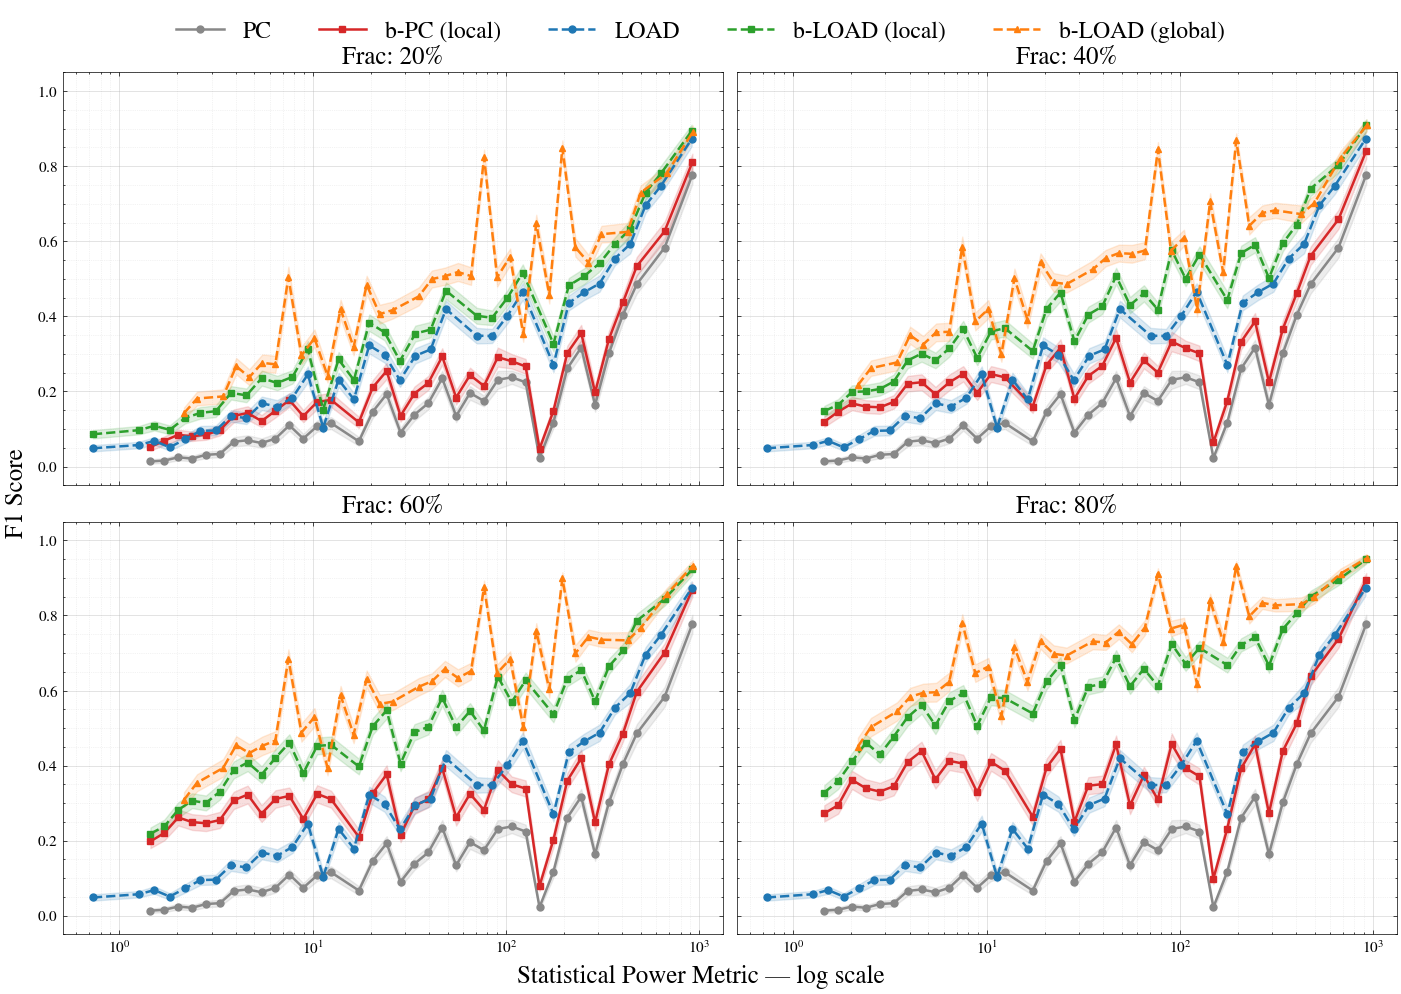

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots

# Apply SciencePlots style
plt.style.use(["science", "no-latex"])

# ── Helper: bin by complexity_metric, then aggregate ─────────────────────────
def _agg_by_cx(df, cx_col='complexity_metric', mean_col=None, ci_col=None, n_bins=40):
    lo = df[cx_col][df[cx_col] > 0].min()
    hi = df[cx_col].max()
    bins = np.logspace(np.log10(lo), np.log10(hi), n_bins + 1)
    df = df.copy()
    df['_bin'] = pd.cut(df[cx_col], bins=bins, labels=False, include_lowest=True)
    df['_bin_mid'] = df['_bin'].map(
        lambda b: np.sqrt(bins[int(b)] * bins[int(b) + 1]) if pd.notna(b) else np.nan
    )
    return (
        df.dropna(subset=['_bin'])
        .groupby('_bin_mid')[[mean_col, ci_col]]
        .mean()
        .reset_index()
        .rename(columns={'_bin_mid': cx_col})
        .sort_values(cx_col)
    )

# ── Static aggregates (BK-independent) ───────────────────────────────────────
agg_pc_f1  = _agg_by_cx(df_pc,         mean_col='f1_mean',           ci_col='ci_f1')
agg_lo_f1  = _agg_by_cx(df_load_no_bk, mean_col='f1_without_b_mean', ci_col='ci_f1_without_b')

# ── Plot config ───────────────────────────────────────────────────────────────
# 4 fractions to perfectly fill a 2x2 grid
TARGET_FRACS = [0.2, 0.4, 0.6, 0.8]

# 5 variants palette
COLORS = {
    'pc':          '#888888',   # grey   — PC
    'bpc':         '#d62728',   # red    — b-PC (local)
    'load':        '#1f77b4',   # blue   — LOAD
    'bload_local': '#2ca02c',   # green  — b-LOAD (local)
    'bload_glob':  '#ff7f0e',   # orange — b-LOAD (global)
}

# Adjusted format for 2x2 layout
fig, axes = plt.subplots(
    2, 2, 
    figsize=(14, 10), # Shrunk width from 28 to 14 for a 2-column grid
    sharex=True, 
    sharey=True,
    layout='constrained' 
)
axes = axes.flatten()

def _plot(ax, df_agg, mean_col, ci_col, color, label, linestyle='-', marker='o', ci_alpha=0.15):
    x  = df_agg['complexity_metric']
    y  = df_agg[mean_col]
    ci = df_agg[ci_col]
    ax.plot(x, y, color=color, label=label,
            linestyle=linestyle, marker=marker, markersize=5, linewidth=1.8)
    ax.fill_between(x, y - ci, y + ci, color=color, alpha=ci_alpha)

for i, ax in enumerate(axes):
    if i >= len(TARGET_FRACS):
        ax.set_visible(False)
        continue

    frac = TARGET_FRACS[i]
    
    # Filter datasets for the current fraction
    sub_bpc   = df_bpc         [np.isclose(df_bpc         ['fraction_required'], frac)]
    sub_load  = df_load        [np.isclose(df_load        ['fraction_required'], frac)]
    sub_bglob = df_bload_global[np.isclose(df_bload_global['fraction_required'], frac)]

    # PC — grey solid
    _plot(ax, agg_pc_f1, 'f1_mean', 'ci_f1', COLORS['pc'], 'PC', linestyle='-', marker='o')

    # b-PC (local) — red solid
    if not sub_bpc.empty:
        agg = _agg_by_cx(sub_bpc, mean_col='f1_mean', ci_col='ci_f1')
        _plot(ax, agg, 'f1_mean', 'ci_f1', COLORS['bpc'], 'b-PC (local)', linestyle='-', marker='s')

    # LOAD (no BK) — blue dashed
    _plot(ax, agg_lo_f1, 'f1_without_b_mean', 'ci_f1_without_b', COLORS['load'], 'LOAD', linestyle='--', marker='o')

    # b-LOAD (local) — green dashed
    if not sub_load.empty:
        agg = _agg_by_cx(sub_load, mean_col='f1_with_b_mean', ci_col='ci_f1_with_b')
        _plot(ax, agg, 'f1_with_b_mean', 'ci_f1_with_b', COLORS['bload_local'], 'b-LOAD (local)', linestyle='--', marker='s')

    # b-LOAD (global) — orange dashed
    if not sub_bglob.empty:
        agg = _agg_by_cx(sub_bglob, mean_col='f1_with_b_mean', ci_col='ci_f1_with_b')
        _plot(ax, agg, 'f1_with_b_mean', 'ci_f1_with_b', COLORS['bload_glob'], 'b-LOAD (global)', linestyle='--', marker='^')

    ax.set_title(f'Frac: {frac:.0%}', fontsize=18, pad=6)
    ax.set_xscale('log')
    
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks(np.arange(0, 1.1, 0.2))
    ax.tick_params(axis='both', which='major', labelsize=11)
    
    # Optional: Keep custom grid over SciencePlots default if you prefer this style
    ax.grid(True, which='major', linestyle='-', alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', alpha=0.3)

# Global labels
fig.supxlabel('Statistical Power Metric — log scale', fontsize=18)
fig.supylabel('F1 Score', fontsize=18)

# Legend at the top center
handles, labels = axes[0].get_legend_handles_labels()
# Fontsize reduced to fit the 5-item legend comfortably over 2 columns
fig.legend(handles, labels, loc='outside upper center', ncol=5, fontsize=17, frameon=False) 

fig.savefig('f1_plot_synth.pdf', bbox_inches='tight')
plt.show()

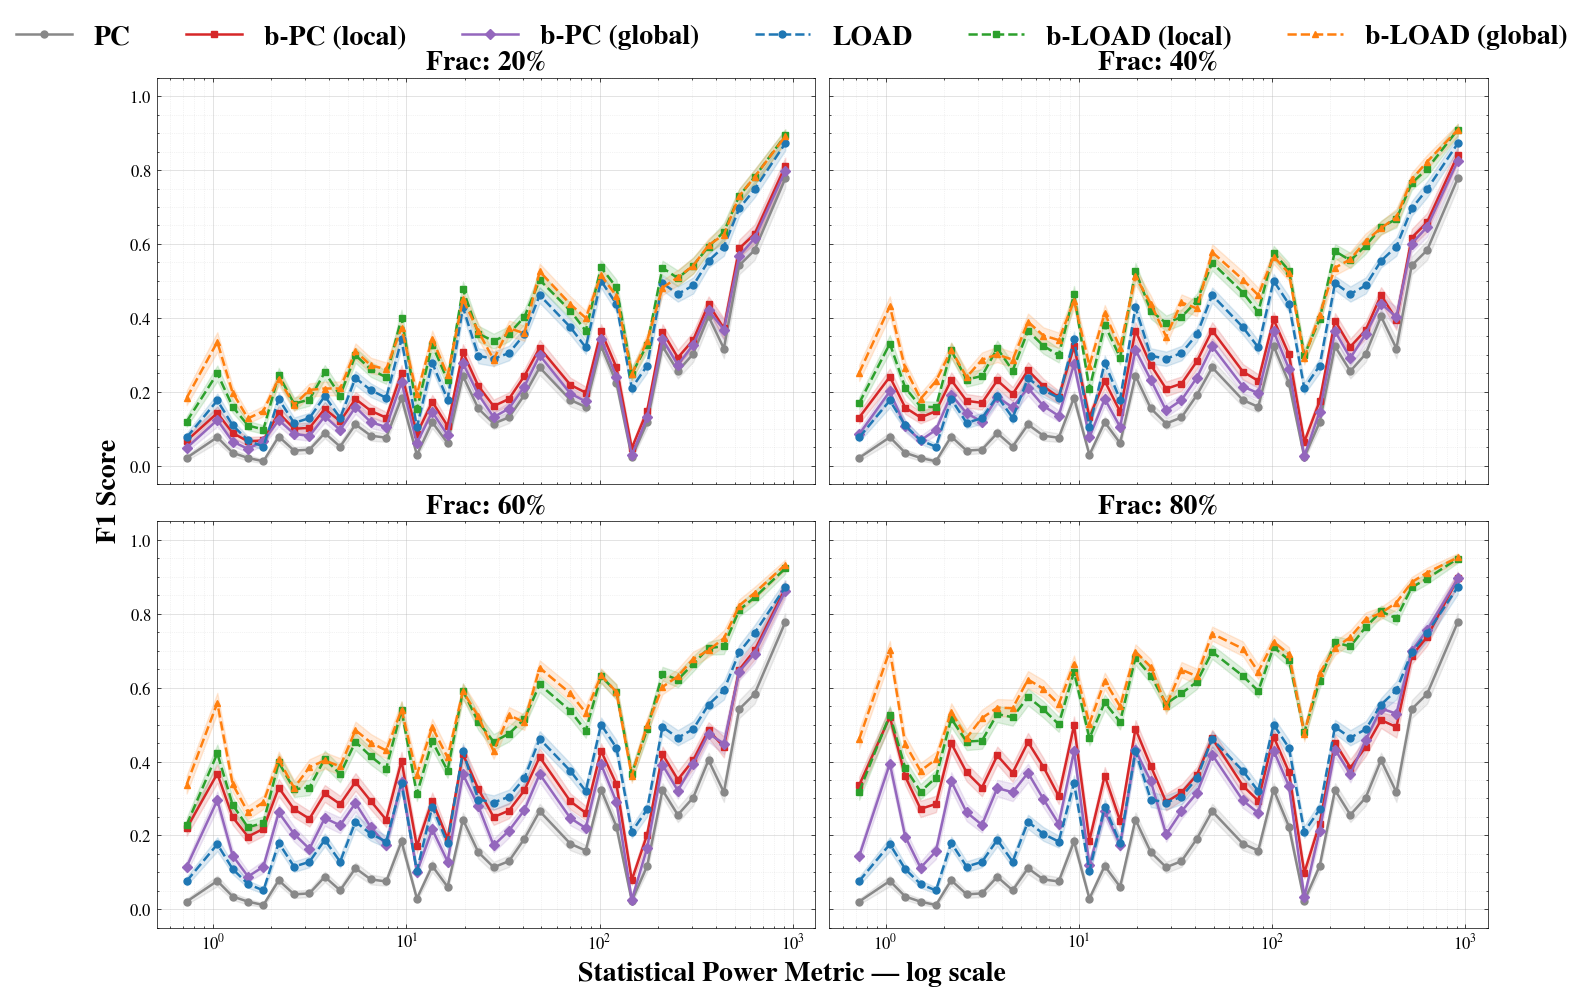

In [12]:
# ── F1 Score — 6 variants (updated with full data + b-PC global) ─────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(["science", "no-latex"])

def _agg_by_cx(df, cx_col='complexity_metric', mean_col=None, ci_col=None, n_bins=40):
    lo = df[cx_col][df[cx_col] > 0].min()
    hi = df[cx_col].max()
    bins = np.logspace(np.log10(lo), np.log10(hi), n_bins + 1)
    df = df.copy()
    df['_bin'] = pd.cut(df[cx_col], bins=bins, labels=False, include_lowest=True)
    df['_bin_mid'] = df['_bin'].map(
        lambda b: np.sqrt(bins[int(b)] * bins[int(b) + 1]) if pd.notna(b) else np.nan
    )
    return (
        df.dropna(subset=['_bin'])
        .groupby('_bin_mid')[[mean_col, ci_col]]
        .mean().reset_index()
        .rename(columns={'_bin_mid': cx_col})
        .sort_values(cx_col)
    )

# BK-independent aggregates (use full data range)
agg_pc_f1  = _agg_by_cx(df_pc,         mean_col='f1_mean',           ci_col='ci_f1')
agg_lo_f1  = _agg_by_cx(df_load_no_bk, mean_col='f1_without_b_mean', ci_col='ci_f1_without_b')

COLORS = {
    'pc':          '#888888',   # grey        — PC
    'bpc':         '#d62728',   # red         — b-PC (local)
    'bpc_glob':    '#9467bd',   # purple      — b-PC (global)
    'load':        '#1f77b4',   # blue        — LOAD
    'bload_local': '#2ca02c',   # green       — b-LOAD (local)
    'bload_glob':  '#ff7f0e',   # orange      — b-LOAD (global)
}

TARGET_FRACS = [0.2, 0.4, 0.6, 0.8]

fig, axes = plt.subplots(2, 2, figsize=(14, 10),
                         sharex=True, sharey=True, layout='constrained')
axes = axes.flatten()

def _plot(ax, df_agg, mean_col, ci_col, color, label,
          linestyle='-', marker='o', ci_alpha=0.15):
    x, y, ci = df_agg['complexity_metric'], df_agg[mean_col], df_agg[ci_col]
    ax.plot(x, y, color=color, label=label,
            linestyle=linestyle, marker=marker, markersize=5, linewidth=1.8)
    ax.fill_between(x, y - ci, y + ci, color=color, alpha=ci_alpha)

for i, ax in enumerate(axes):
    if i >= len(TARGET_FRACS):
        ax.set_visible(False); continue

    frac = TARGET_FRACS[i]
    sub_bpc    = df_bpc        [np.isclose(df_bpc        ['fraction_required'], frac)]
    sub_bpcg   = df_bpc_global [np.isclose(df_bpc_global ['fraction_required'], frac)]
    sub_load   = df_load       [np.isclose(df_load       ['fraction_required'], frac)]
    sub_bglob  = df_bload_global[np.isclose(df_bload_global['fraction_required'], frac)]

    _plot(ax, agg_pc_f1, 'f1_mean', 'ci_f1',
          COLORS['pc'],    'PC',             linestyle='-',  marker='o')
    if not sub_bpc.empty:
        _plot(ax, _agg_by_cx(sub_bpc,  mean_col='f1_mean', ci_col='ci_f1'),
              'f1_mean', 'ci_f1', COLORS['bpc'],  'b-PC (local)',  linestyle='-',  marker='s')
    if not sub_bpcg.empty:
        _plot(ax, _agg_by_cx(sub_bpcg, mean_col='f1_mean', ci_col='ci_f1'),
              'f1_mean', 'ci_f1', COLORS['bpc_glob'], 'b-PC (global)', linestyle='-', marker='D')
    _plot(ax, agg_lo_f1, 'f1_without_b_mean', 'ci_f1_without_b',
          COLORS['load'],  'LOAD',            linestyle='--', marker='o')
    if not sub_load.empty:
        _plot(ax, _agg_by_cx(sub_load, mean_col='f1_with_b_mean', ci_col='ci_f1_with_b'),
              'f1_with_b_mean', 'ci_f1_with_b',
              COLORS['bload_local'], 'b-LOAD (local)', linestyle='--', marker='s')
    if not sub_bglob.empty:
        _plot(ax, _agg_by_cx(sub_bglob, mean_col='f1_with_b_mean', ci_col='ci_f1_with_b'),
              'f1_with_b_mean', 'ci_f1_with_b',
              COLORS['bload_glob'], 'b-LOAD (global)', linestyle='--', marker='^')

    # Add fontweight='bold' to the axes title
    ax.set_title(f'Frac: {frac:.0%}', fontsize=20, pad=6, fontweight='bold')
    ax.set_xscale('log')
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks(np.arange(0, 1.1, 0.2))
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.grid(True, which='major', linestyle='-', alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', alpha=0.3)

# Add fontweight='bold' to the super x and y labels
fig.supxlabel('Statistical Power Metric — log scale', fontsize=20, fontweight='bold')
fig.supylabel('F1 Score', fontsize=20, fontweight='bold')

handles, labels = axes[0].get_legend_handles_labels()

# For the legend, replace `fontsize=20` with the `prop` dictionary
fig.legend(handles, labels, loc='outside upper center', ncol=6, frameon=False, prop={'size': 20, 'weight': 'bold'})
fig.savefig('f1_plot_synth_v2.pdf', bbox_inches='tight')


<frozen importlib._bootstrap>:491: RuntimeWarning: The global interpreter lock (GIL) has been enabled to load module 'fontTools.misc.bezierTools', which has not declared that it can run safely without the GIL. To override this behavior and keep the GIL disabled (at your own risk), run with PYTHON_GIL=0 or -Xgil=0.


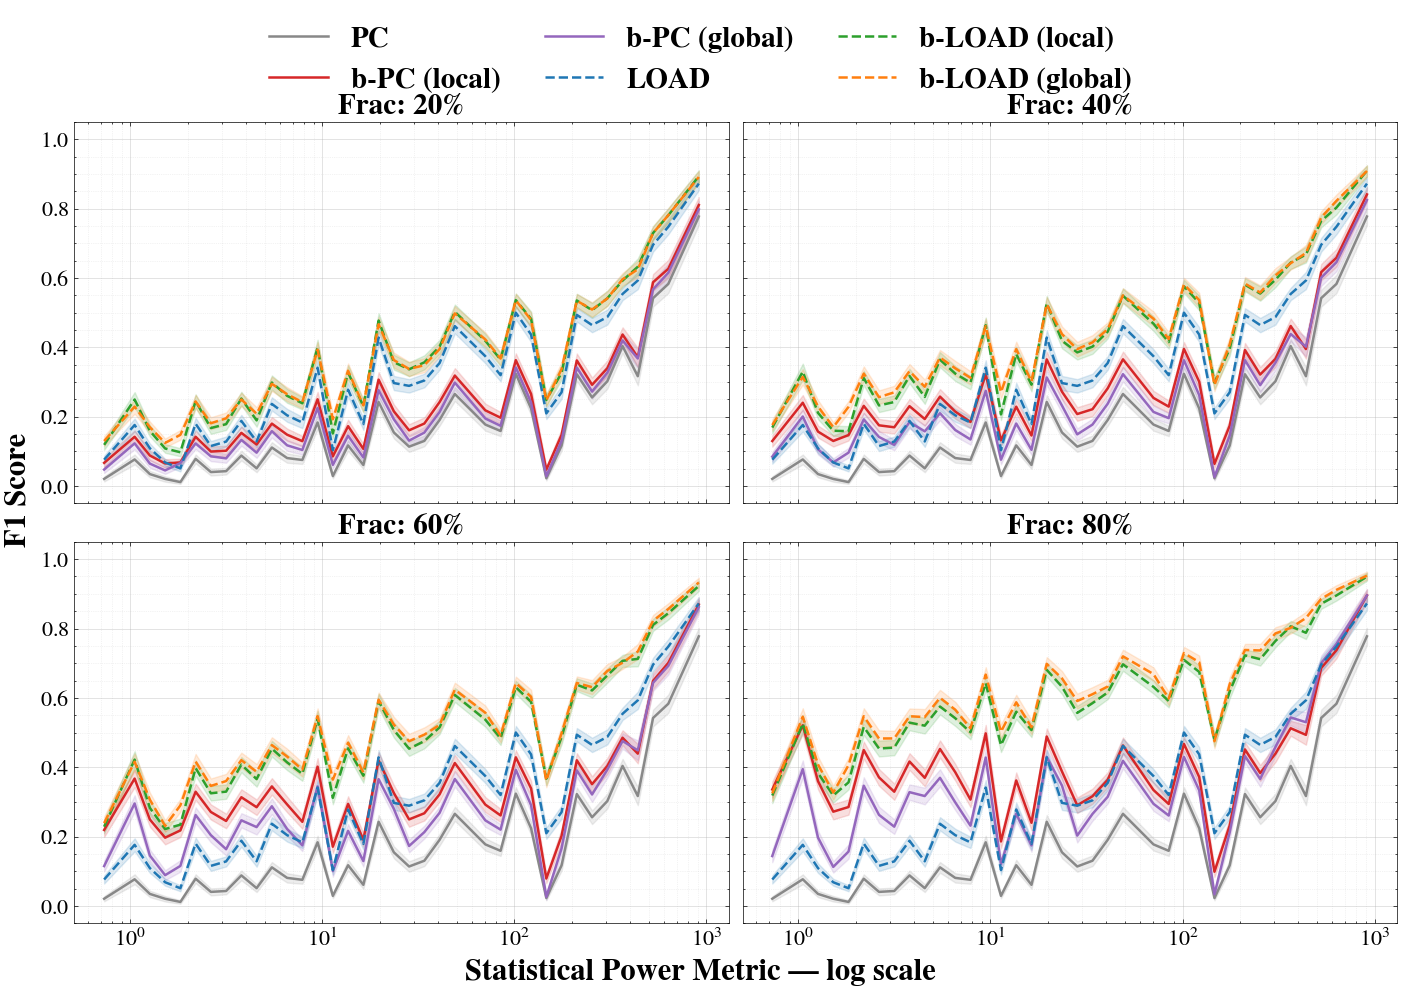

In [15]:
# ── F1 Score — 6 variants (updated with full data + b-PC global) ─────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(["science", "no-latex"])

def _agg_by_cx(df, cx_col='complexity_metric', mean_col=None, ci_col=None, n_bins=40):
    lo = df[cx_col][df[cx_col] > 0].min()
    hi = df[cx_col].max()
    bins = np.logspace(np.log10(lo), np.log10(hi), n_bins + 1)
    df = df.copy()
    df['_bin'] = pd.cut(df[cx_col], bins=bins, labels=False, include_lowest=True)
    df['_bin_mid'] = df['_bin'].map(
        lambda b: np.sqrt(bins[int(b)] * bins[int(b) + 1]) if pd.notna(b) else np.nan
    )
    return (
        df.dropna(subset=['_bin'])
        .groupby('_bin_mid')[[mean_col, ci_col]]
        .mean().reset_index()
        .rename(columns={'_bin_mid': cx_col})
        .sort_values(cx_col)
    )

# BK-independent aggregates (use full data range)
agg_pc_f1  = _agg_by_cx(df_pc,         mean_col='f1_mean',           ci_col='ci_f1')
agg_lo_f1  = _agg_by_cx(df_load_no_bk, mean_col='f1_without_b_mean', ci_col='ci_f1_without_b')

COLORS = {
    'pc':          '#888888',   # grey        — PC
    'bpc':         '#d62728',   # red         — b-PC (local)
    'bpc_glob':    '#9467bd',   # purple      — b-PC (global)
    'load':        '#1f77b4',   # blue        — LOAD
    'bload_local': '#2ca02c',   # green       — b-LOAD (local)
    'bload_glob':  '#ff7f0e',   # orange      — b-LOAD (global)
}

TARGET_FRACS = [0.2, 0.4, 0.6, 0.8]

fig, axes = plt.subplots(2, 2, figsize=(14, 10),
                         sharex=True, sharey=True, layout='constrained')
axes = axes.flatten()

def _plot(ax, df_agg, mean_col, ci_col, color, label,
          linestyle='-', ci_alpha=0.15):
    x, y, ci = df_agg['complexity_metric'], df_agg[mean_col], df_agg[ci_col]
    ax.plot(x, y, color=color, label=label,
            linestyle=linestyle, linewidth=1.8)
    ax.fill_between(x, y - ci, y + ci, color=color, alpha=ci_alpha)

for i, ax in enumerate(axes):
    if i >= len(TARGET_FRACS):
        ax.set_visible(False); continue

    frac = TARGET_FRACS[i]
    sub_bpc    = df_bpc        [np.isclose(df_bpc        ['fraction_required'], frac)]
    sub_bpcg   = df_bpc_global [np.isclose(df_bpc_global ['fraction_required'], frac)]
    sub_load   = df_load       [np.isclose(df_load       ['fraction_required'], frac)]
    sub_bglob  = df_bload_global[np.isclose(df_bload_global['fraction_required'], frac)]

    _plot(ax, agg_pc_f1, 'f1_mean', 'ci_f1',
          COLORS['pc'],    'PC',             linestyle='-')
    if not sub_bpc.empty:
        _plot(ax, _agg_by_cx(sub_bpc,  mean_col='f1_mean', ci_col='ci_f1'),
              'f1_mean', 'ci_f1', COLORS['bpc'],  'b-PC (local)',  linestyle='-')
    if not sub_bpcg.empty:
        _plot(ax, _agg_by_cx(sub_bpcg, mean_col='f1_mean', ci_col='ci_f1'),
              'f1_mean', 'ci_f1', COLORS['bpc_glob'], 'b-PC (global)', linestyle='-')
    _plot(ax, agg_lo_f1, 'f1_without_b_mean', 'ci_f1_without_b',
          COLORS['load'],  'LOAD',            linestyle='--')
    if not sub_load.empty:
        _plot(ax, _agg_by_cx(sub_load, mean_col='f1_with_b_mean', ci_col='ci_f1_with_b'),
              'f1_with_b_mean', 'ci_f1_with_b',
              COLORS['bload_local'], 'b-LOAD (local)', linestyle='--')
    if not sub_bglob.empty:
        _plot(ax, _agg_by_cx(sub_bglob, mean_col='f1_with_b_mean', ci_col='ci_f1_with_b'),
              'f1_with_b_mean', 'ci_f1_with_b',
              COLORS['bload_glob'], 'b-LOAD (global)', linestyle='--')

    # Add fontweight='bold' to the axes title
    ax.set_title(f'Frac: {frac:.0%}', fontsize=21, pad=6, fontweight='bold')
    ax.set_xscale('log')
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks(np.arange(0, 1.1, 0.2))
    ax.tick_params(axis='both', which='major', labelsize=16)
    ax.grid(True, which='major', linestyle='-', alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', alpha=0.3)

# Add fontweight='bold' to the super x and y labels
fig.supxlabel('Statistical Power Metric — log scale', fontsize=22, fontweight='bold')
fig.supylabel('F1 Score', fontsize=22, fontweight='bold')

handles, labels = axes[0].get_legend_handles_labels()

# Changed ncol=6 to ncol=3. 
# Added columnspacing=1.5 to keep the items nicely separated.
fig.legend(handles, labels, loc='outside upper center', ncol=3, 
           frameon=False, prop={'size': 21, 'weight': 'bold'}, columnspacing=1.5)

fig.savefig('f1_plot_synth_v2.pdf', bbox_inches='tight')
plt.show()


## Graphical analysis: Intervention Distance results

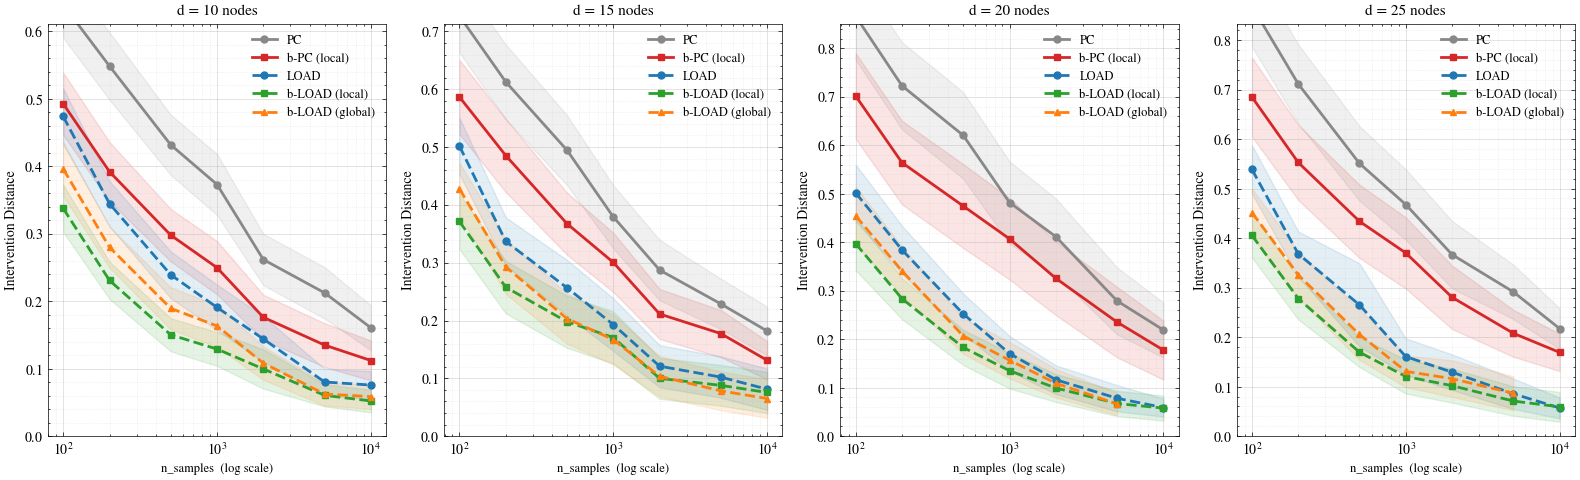

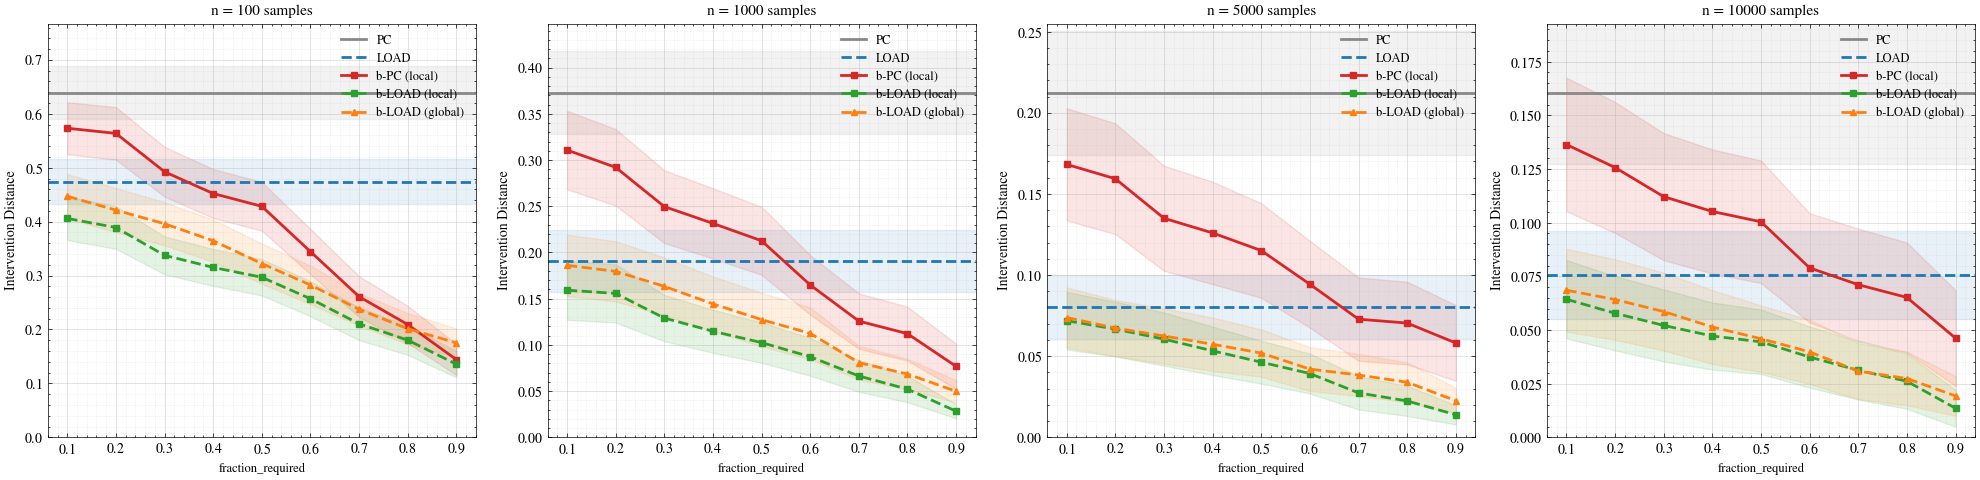

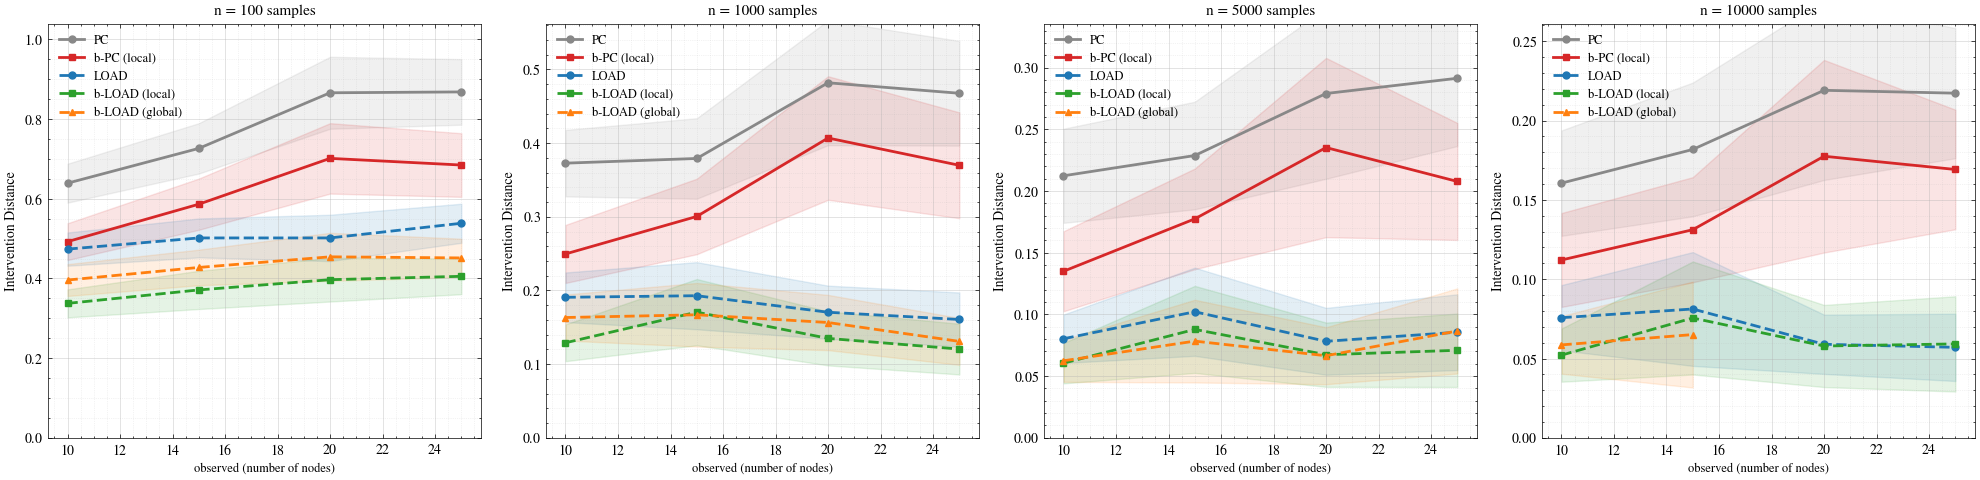

In [8]:
# ══════════════════════════════════════════════════════════════════════════════
#  Intervention Distance — 5 variants (local + global b-LOAD), ER2
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ER = 2.0
df_pc_er2    = df_pc         [np.isclose(df_pc         ['exp_degree'], ER)].copy()
df_bpc_er2   = df_bpc        [np.isclose(df_bpc        ['exp_degree'], ER)].copy()
df_load_er2  = df_load       [np.isclose(df_load       ['exp_degree'], ER)].copy()
df_bglob_er2 = df_bload_global[np.isclose(df_bload_global['exp_degree'], ER)].copy()

COLORS = {
    'pc':          '#888888',
    'bpc':         '#d62728',
    'load':        '#1f77b4',
    'bload_local': '#2ca02c',
    'bload_glob':  '#ff7f0e',
}

def _pline(ax, x, y, ci, color, label, linestyle='-', marker='o', alpha=0.12):
    ax.plot(x, y, color=color, label=label, linestyle=linestyle,
            marker=marker, markersize=5, linewidth=2)
    ax.fill_between(x, y - ci, y + ci, color=color, alpha=alpha)

def _cap_ylim(ax, *series, pct=95, margin=1.20):
    all_vals = [v for s in series for v in s if not np.isnan(v)]
    if all_vals:
        ax.set_ylim(bottom=0, top=np.nanpercentile(all_vals, pct) * margin)

def _fmt(ax, xlabel, xscale='linear', legend_loc='upper right'):
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel('Intervention Distance', fontsize=10)
    ax.set_xscale(xscale)
    ax.grid(True, which='major', linestyle='-',  alpha=0.5)
    ax.grid(True, which='minor', linestyle=':',  alpha=0.3)
    ax.legend(fontsize=9, framealpha=0.9, loc=legend_loc)

# ─────────────────────────────────────────────────────────────────────────────
# A — Data efficiency  |  Fixed: ER2, frac_req=0.3  |  X: n_samples  |  panels: d
# ─────────────────────────────────────────────────────────────────────────────
FRAC_A = 0.3
D_A    = [10, 15, 20, 25]

fig_a, axes_a = plt.subplots(1, len(D_A), figsize=(16, 5), sharey=False)

# TITLE REMOVED FOR ACM FORMAT

for ax, d in zip(axes_a, D_A):
    pc_s   = df_pc_er2   [df_pc_er2   ['observed'] == d].sort_values('n_samples')
    bpc_s  = df_bpc_er2  [(df_bpc_er2 ['observed'] == d) &
                           np.isclose(df_bpc_er2 ['fraction_required'], FRAC_A)].sort_values('n_samples')
    lo_s   = (df_load_er2 [df_load_er2 ['observed'] == d]
              .drop_duplicates('n_samples').sort_values('n_samples'))
    blo_s  = df_load_er2  [(df_load_er2 ['observed'] == d) &
                            np.isclose(df_load_er2 ['fraction_required'], FRAC_A)].sort_values('n_samples')
    bgl_s  = df_bglob_er2 [(df_bglob_er2['observed'] == d) &
                            np.isclose(df_bglob_er2['fraction_required'], FRAC_A)].sort_values('n_samples')

    _pline(ax, pc_s['n_samples'], pc_s['int_dist_mean'], pc_s['ci_int_dist'],
           COLORS['pc'],    'PC',             linestyle='-',  marker='o')
    if not bpc_s.empty:
        _pline(ax, bpc_s['n_samples'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],   'b-PC (local)',   linestyle='-',  marker='s')
    _pline(ax, lo_s['n_samples'], lo_s['int_dist_without_b_mean'], lo_s['ci_int_dist_without_b'],
           COLORS['load'],  'LOAD',            linestyle='--', marker='o')
    if not blo_s.empty:
        _pline(ax, blo_s['n_samples'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', linestyle='--', marker='s')
    if not bgl_s.empty:
        _pline(ax, bgl_s['n_samples'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', linestyle='--', marker='^')

    _cap_ylim(ax,
              pc_s ['int_dist_mean'],
              lo_s ['int_dist_without_b_mean'],
              bpc_s['int_dist_mean']             if not bpc_s.empty else [],
              blo_s['int_dist_with_b_mean']       if not blo_s.empty else [],
              bgl_s['int_dist_with_b_mean']       if not bgl_s.empty else [])
    ax.set_title(f'd = {d} nodes', fontsize=11)
    _fmt(ax, 'n_samples  (log scale)', xscale='log', legend_loc='upper right')

plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# B — BK sensitivity  |  Fixed: ER2, d=10  |  X: frac_req  |  panels: n_samples
# ─────────────────────────────────────────────────────────────────────────────
D_B = 10
all_n = sorted(set(df_bpc_er2['n_samples'].unique()) | set(df_bglob_er2['n_samples'].unique()))
N_B  = [n for n in [100, 1000, 5000, 10000] if n in all_n]

fig_b, axes_b = plt.subplots(1, len(N_B), figsize=(5 * len(N_B), 5), sharey=False)
if len(N_B) == 1: axes_b = [axes_b]

# TITLE REMOVED FOR ACM FORMAT

for ax, n in zip(axes_b, N_B):
    pc_row  = df_pc_er2  [(df_pc_er2  ['observed'] == D_B) & (df_pc_er2  ['n_samples'] == n)]
    bpc_s   = df_bpc_er2 [(df_bpc_er2 ['observed'] == D_B) & (df_bpc_er2 ['n_samples'] == n)].sort_values('fraction_required')
    lo_rows = df_load_er2[(df_load_er2['observed'] == D_B) & (df_load_er2['n_samples'] == n)]
    blo_s   = lo_rows.sort_values('fraction_required')
    lo_row  = lo_rows.drop_duplicates('n_samples')
    bgl_s   = df_bglob_er2[(df_bglob_er2['observed'] == D_B) & (df_bglob_er2['n_samples'] == n)].sort_values('fraction_required')

    if not pc_row.empty:
        pc_y, pc_ci = pc_row['int_dist_mean'].iloc[0], pc_row['ci_int_dist'].iloc[0]
        ax.axhline(pc_y, color=COLORS['pc'], linewidth=2, linestyle='-', label='PC')
        ax.axhspan(pc_y - pc_ci, pc_y + pc_ci, color=COLORS['pc'], alpha=0.10)
    if not lo_row.empty:
        lo_y, lo_ci = lo_row['int_dist_without_b_mean'].iloc[0], lo_row['ci_int_dist_without_b'].iloc[0]
        ax.axhline(lo_y, color=COLORS['load'], linewidth=2, linestyle='--', label='LOAD')
        ax.axhspan(lo_y - lo_ci, lo_y + lo_ci, color=COLORS['load'], alpha=0.10)

    if not bpc_s.empty:
        _pline(ax, bpc_s['fraction_required'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],   'b-PC (local)',    linestyle='-',  marker='s')
    if not blo_s.empty:
        _pline(ax, blo_s['fraction_required'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', linestyle='--', marker='s')
    if not bgl_s.empty:
        _pline(ax, bgl_s['fraction_required'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', linestyle='--', marker='^')

    _cap_ylim(ax,
              pc_row['int_dist_mean']          if not pc_row.empty else [],
              lo_row['int_dist_without_b_mean'] if not lo_row.empty else [],
              bpc_s ['int_dist_mean']           if not bpc_s.empty  else [],
              blo_s ['int_dist_with_b_mean']    if not blo_s.empty  else [],
              bgl_s ['int_dist_with_b_mean']    if not bgl_s.empty  else [],
              pct=100)
    ax.set_title(f'n = {n} samples', fontsize=11)
    _fmt(ax, 'fraction_required', legend_loc='upper right')

plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# C — Scalability  |  Fixed: ER2, frac_req=0.3  |  X: observed  |  panels: n_samples
# ─────────────────────────────────────────────────────────────────────────────
FRAC_C = 0.3
N_C    = [n for n in [100, 1000, 5000, 10000] if n in all_n]

fig_c, axes_c = plt.subplots(1, len(N_C), figsize=(5 * len(N_C), 5), sharey=False)
if len(N_C) == 1: axes_c = [axes_c]

# TITLE REMOVED FOR ACM FORMAT

for ax, n in zip(axes_c, N_C):
    pc_s  = df_pc_er2   [df_pc_er2   ['n_samples'] == n].sort_values('observed')
    bpc_s = df_bpc_er2  [(df_bpc_er2 ['n_samples'] == n) &
                          np.isclose(df_bpc_er2['fraction_required'], FRAC_C)].sort_values('observed')
    lo_s  = (df_load_er2[df_load_er2['n_samples'] == n]
             .drop_duplicates('observed').sort_values('observed'))
    blo_s = df_load_er2 [(df_load_er2['n_samples'] == n) &
                          np.isclose(df_load_er2['fraction_required'], FRAC_C)].sort_values('observed')
    bgl_s = df_bglob_er2[(df_bglob_er2['n_samples'] == n) &
                          np.isclose(df_bglob_er2['fraction_required'], FRAC_C)].sort_values('observed')

    _pline(ax, pc_s['observed'], pc_s['int_dist_mean'], pc_s['ci_int_dist'],
           COLORS['pc'],    'PC',             linestyle='-',  marker='o')
    if not bpc_s.empty:
        _pline(ax, bpc_s['observed'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],   'b-PC (local)',   linestyle='-',  marker='s')
    _pline(ax, lo_s['observed'], lo_s['int_dist_without_b_mean'], lo_s['ci_int_dist_without_b'],
           COLORS['load'],  'LOAD',            linestyle='--', marker='o')
    if not blo_s.empty:
        _pline(ax, blo_s['observed'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', linestyle='--', marker='s')
    if not bgl_s.empty:
        _pline(ax, bgl_s['observed'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', linestyle='--', marker='^')

    _cap_ylim(ax,
              pc_s ['int_dist_mean'],
              lo_s ['int_dist_without_b_mean'],
              bpc_s['int_dist_mean']          if not bpc_s.empty else [],
              blo_s['int_dist_with_b_mean']   if not blo_s.empty else [],
              bgl_s['int_dist_with_b_mean']   if not bgl_s.empty else [])
    ax.set_title(f'n = {n} samples', fontsize=11)
    _fmt(ax, 'observed (number of nodes)', legend_loc='upper left')

plt.tight_layout()
plt.show()

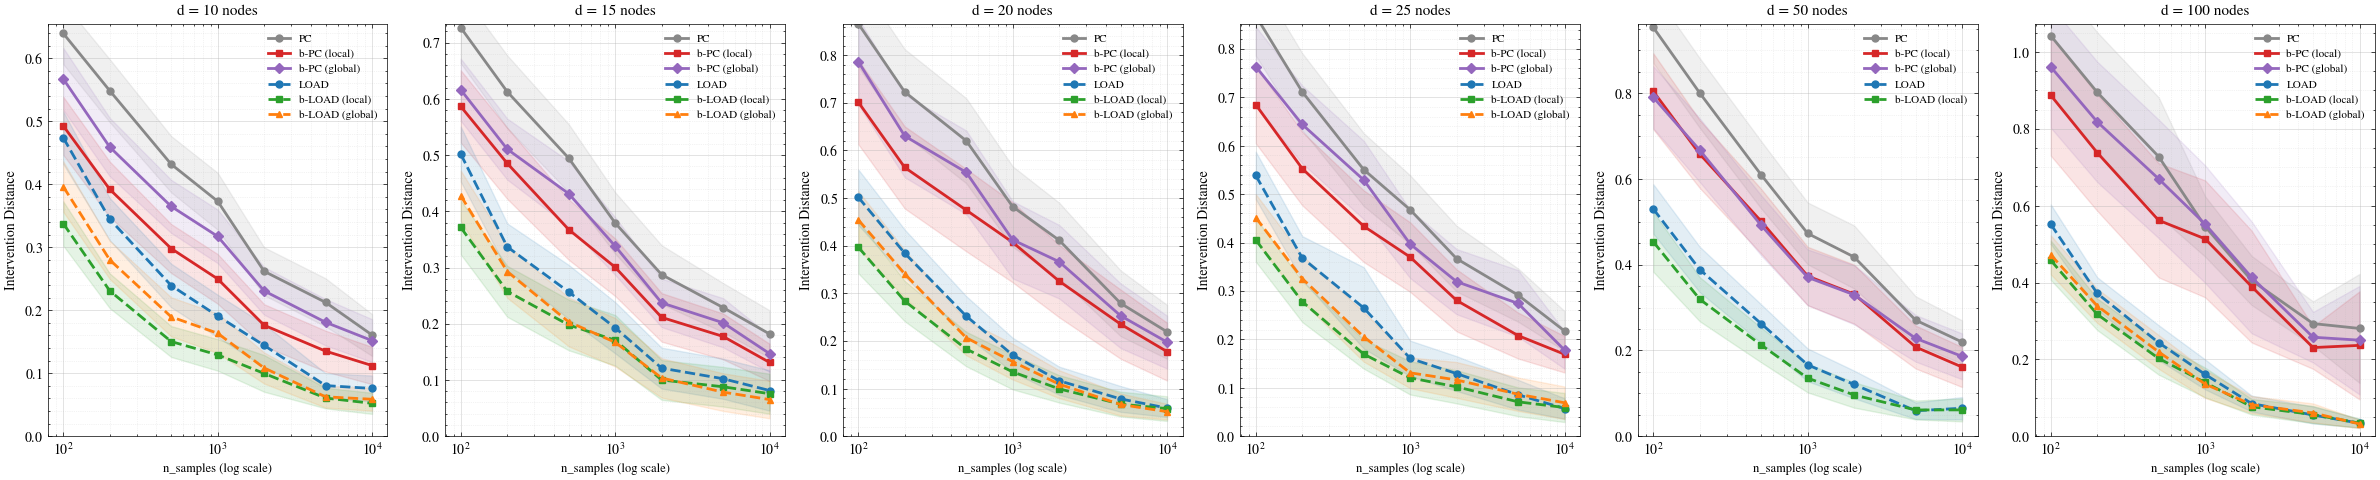

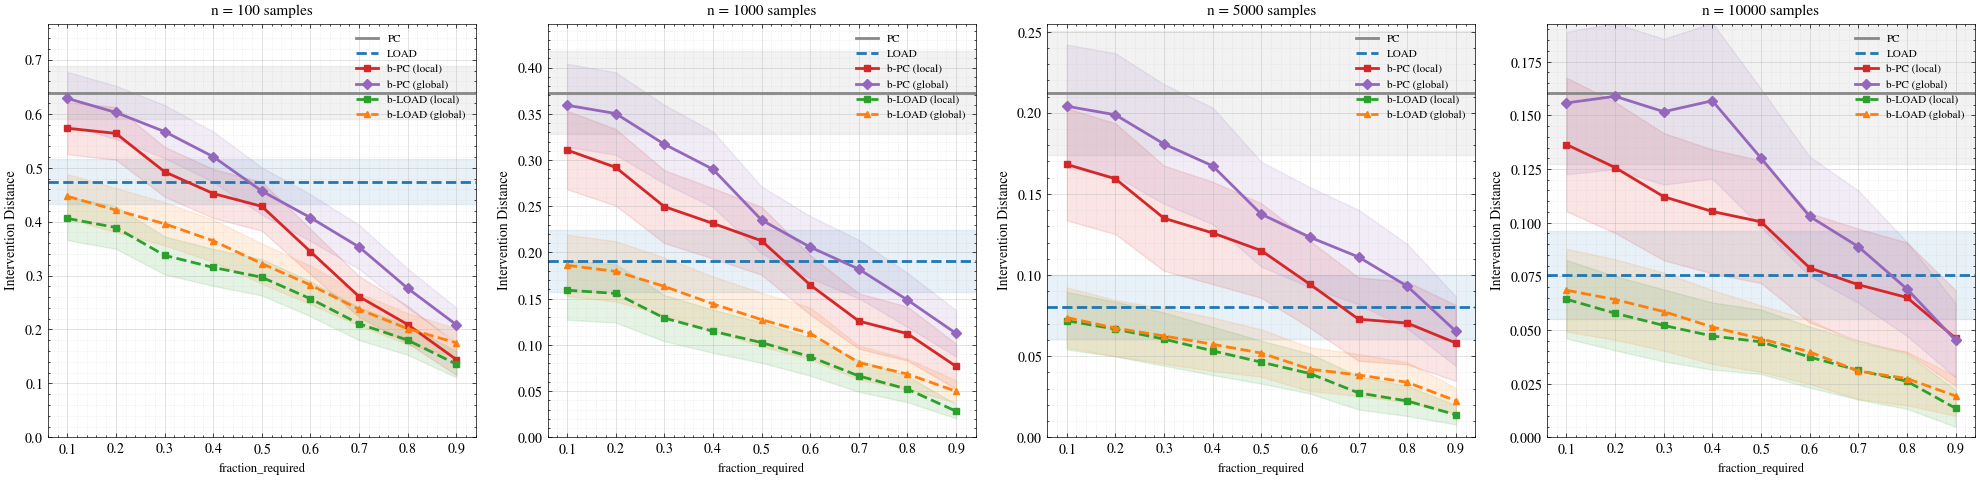

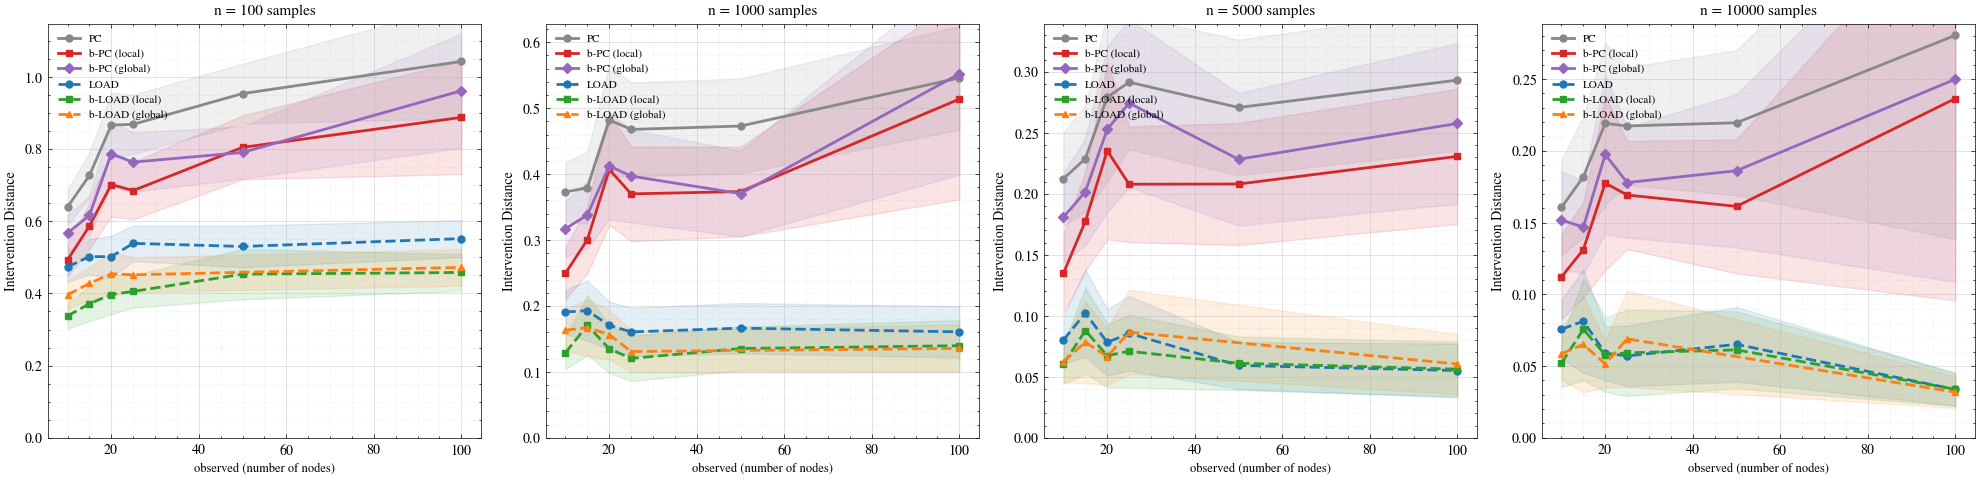

In [10]:
# ══════════════════════════════════════════════════════════════════════════════
#  Intervention Distance — 6 variants, ER2 (updated with full data)
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ER = 2.0
df_pc_er2    = df_pc         [np.isclose(df_pc         ['exp_degree'], ER)].copy()
df_bpc_er2   = df_bpc        [np.isclose(df_bpc        ['exp_degree'], ER)].copy()
df_bpcg_er2  = df_bpc_global [np.isclose(df_bpc_global ['exp_degree'], ER)].copy()
df_load_er2  = df_load       [np.isclose(df_load       ['exp_degree'], ER)].copy()
df_bglob_er2 = df_bload_global[np.isclose(df_bload_global['exp_degree'], ER)].copy()

COLORS = {
    'pc':          '#888888',
    'bpc':         '#d62728',
    'bpc_glob':    '#9467bd',
    'load':        '#1f77b4',
    'bload_local': '#2ca02c',
    'bload_glob':  '#ff7f0e',
}

def _pline(ax, x, y, ci, color, label, linestyle='-', marker='o', alpha=0.12):
    ax.plot(x, y, color=color, label=label, linestyle=linestyle,
            marker=marker, markersize=5, linewidth=2)
    ax.fill_between(x, y - ci, y + ci, color=color, alpha=alpha)

def _cap_ylim(ax, *series, pct=95, margin=1.20):
    all_vals = [v for s in series for v in s if not np.isnan(v)]
    if all_vals:
        ax.set_ylim(bottom=0, top=np.nanpercentile(all_vals, pct) * margin)

def _fmt(ax, xlabel, xscale='linear', legend_loc='upper right'):
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel('Intervention Distance', fontsize=10)
    ax.set_xscale(xscale)
    ax.grid(True, which='major', linestyle='-',  alpha=0.5)
    ax.grid(True, which='minor', linestyle=':',  alpha=0.3)
    ax.legend(fontsize=8, framealpha=0.9, loc=legend_loc)

all_n = sorted(set(df_bpc_er2['n_samples'].unique()) |
               set(df_bpcg_er2['n_samples'].unique()) |
               set(df_bglob_er2['n_samples'].unique()))

# ─────────────────────────────────────────────────────────────────────────────
# A — Data efficiency  |  ER2, frac_req=0.3  |  X: n_samples  |  panels: d
# ─────────────────────────────────────────────────────────────────────────────
FRAC_A = 0.3
D_A = sorted(df_pc_er2['observed'].unique())

fig_a, axes_a = plt.subplots(1, len(D_A), figsize=(4 * len(D_A), 5), sharey=False)
if len(D_A) == 1: axes_a = [axes_a]

for ax, d in zip(axes_a, D_A):
    pc_s   = df_pc_er2  [df_pc_er2  ['observed'] == d].sort_values('n_samples')
    bpc_s  = df_bpc_er2 [(df_bpc_er2['observed'] == d) & np.isclose(df_bpc_er2['fraction_required'], FRAC_A)].sort_values('n_samples')
    bpcg_s = df_bpcg_er2[(df_bpcg_er2['observed'] == d) & np.isclose(df_bpcg_er2['fraction_required'], FRAC_A)].sort_values('n_samples')
    lo_s   = df_load_er2[df_load_er2['observed'] == d].drop_duplicates('n_samples').sort_values('n_samples')
    blo_s  = df_load_er2[(df_load_er2['observed'] == d) & np.isclose(df_load_er2['fraction_required'], FRAC_A)].sort_values('n_samples')
    bgl_s  = df_bglob_er2[(df_bglob_er2['observed'] == d) & np.isclose(df_bglob_er2['fraction_required'], FRAC_A)].sort_values('n_samples')

    _pline(ax, pc_s['n_samples'], pc_s['int_dist_mean'], pc_s['ci_int_dist'],
           COLORS['pc'],    'PC',             '-',  'o')
    if not bpc_s.empty:
        _pline(ax, bpc_s['n_samples'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],   'b-PC (local)',   '-',  's')
    if not bpcg_s.empty:
        _pline(ax, bpcg_s['n_samples'], bpcg_s['int_dist_mean'], bpcg_s['ci_int_dist'],
               COLORS['bpc_glob'], 'b-PC (global)', '-',  'D')
    _pline(ax, lo_s['n_samples'], lo_s['int_dist_without_b_mean'], lo_s['ci_int_dist_without_b'],
           COLORS['load'],  'LOAD',            '--', 'o')
    if not blo_s.empty:
        _pline(ax, blo_s['n_samples'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', '--', 's')
    if not bgl_s.empty:
        _pline(ax, bgl_s['n_samples'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', '--', '^')

    _cap_ylim(ax, pc_s['int_dist_mean'], lo_s['int_dist_without_b_mean'],
              bpc_s['int_dist_mean'] if not bpc_s.empty else [],
              bpcg_s['int_dist_mean'] if not bpcg_s.empty else [],
              blo_s['int_dist_with_b_mean'] if not blo_s.empty else [],
              bgl_s['int_dist_with_b_mean'] if not bgl_s.empty else [])
    ax.set_title(f'd = {d} nodes', fontsize=11)
    _fmt(ax, 'n_samples (log scale)', xscale='log')

plt.tight_layout()
plt.savefig('int_dist_A_v2.pdf', bbox_inches='tight')
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# B — BK sensitivity  |  ER2, d=10  |  X: frac_req  |  panels: n_samples
# ─────────────────────────────────────────────────────────────────────────────
D_B = 10
N_B = [n for n in [100, 1000, 5000, 10000] if n in all_n]

fig_b, axes_b = plt.subplots(1, len(N_B), figsize=(5 * len(N_B), 5), sharey=False)
if len(N_B) == 1: axes_b = [axes_b]

for ax, n in zip(axes_b, N_B):
    pc_row  = df_pc_er2  [(df_pc_er2  ['observed'] == D_B) & (df_pc_er2  ['n_samples'] == n)]
    bpc_s   = df_bpc_er2 [(df_bpc_er2 ['observed'] == D_B) & (df_bpc_er2 ['n_samples'] == n)].sort_values('fraction_required')
    bpcg_s  = df_bpcg_er2[(df_bpcg_er2['observed'] == D_B) & (df_bpcg_er2['n_samples'] == n)].sort_values('fraction_required')
    lo_rows = df_load_er2[(df_load_er2['observed'] == D_B) & (df_load_er2['n_samples'] == n)]
    lo_row  = lo_rows.drop_duplicates('n_samples')
    blo_s   = lo_rows.sort_values('fraction_required')
    bgl_s   = df_bglob_er2[(df_bglob_er2['observed'] == D_B) & (df_bglob_er2['n_samples'] == n)].sort_values('fraction_required')

    # Horizontal baselines for BK-invariant methods
    if not pc_row.empty:
        py, pci = pc_row['int_dist_mean'].iloc[0], pc_row['ci_int_dist'].iloc[0]
        ax.axhline(py, color=COLORS['pc'], lw=2, ls='-', label='PC')
        ax.axhspan(py - pci, py + pci, color=COLORS['pc'], alpha=0.10)
    if not lo_row.empty:
        ly, lci = lo_row['int_dist_without_b_mean'].iloc[0], lo_row['ci_int_dist_without_b'].iloc[0]
        ax.axhline(ly, color=COLORS['load'], lw=2, ls='--', label='LOAD')
        ax.axhspan(ly - lci, ly + lci, color=COLORS['load'], alpha=0.10)

    if not bpc_s.empty:
        _pline(ax, bpc_s['fraction_required'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],       'b-PC (local)',    '-',  's')
    if not bpcg_s.empty:
        _pline(ax, bpcg_s['fraction_required'], bpcg_s['int_dist_mean'], bpcg_s['ci_int_dist'],
               COLORS['bpc_glob'],  'b-PC (global)',   '-',  'D')
    if not blo_s.empty:
        _pline(ax, blo_s['fraction_required'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', '--', 's')
    if not bgl_s.empty:
        _pline(ax, bgl_s['fraction_required'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', '--', '^')

    _cap_ylim(ax,
              pc_row['int_dist_mean']          if not pc_row.empty else [],
              lo_row['int_dist_without_b_mean'] if not lo_row.empty else [],
              bpc_s ['int_dist_mean']           if not bpc_s.empty  else [],
              bpcg_s['int_dist_mean']           if not bpcg_s.empty else [],
              blo_s ['int_dist_with_b_mean']    if not blo_s.empty  else [],
              bgl_s ['int_dist_with_b_mean']    if not bgl_s.empty  else [],
              pct=100)
    ax.set_title(f'n = {n} samples', fontsize=11)
    _fmt(ax, 'fraction_required')

plt.tight_layout()
plt.savefig('int_dist_B_v2.pdf', bbox_inches='tight')
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# C — Scalability  |  ER2, frac_req=0.3  |  X: observed  |  panels: n_samples
# ─────────────────────────────────────────────────────────────────────────────
FRAC_C = 0.3
N_C = [n for n in [100, 1000, 5000, 10000] if n in all_n]

fig_c, axes_c = plt.subplots(1, len(N_C), figsize=(5 * len(N_C), 5), sharey=False)
if len(N_C) == 1: axes_c = [axes_c]

for ax, n in zip(axes_c, N_C):
    pc_s   = df_pc_er2  [df_pc_er2  ['n_samples'] == n].sort_values('observed')
    bpc_s  = df_bpc_er2 [(df_bpc_er2['n_samples'] == n) & np.isclose(df_bpc_er2['fraction_required'], FRAC_C)].sort_values('observed')
    bpcg_s = df_bpcg_er2[(df_bpcg_er2['n_samples'] == n) & np.isclose(df_bpcg_er2['fraction_required'], FRAC_C)].sort_values('observed')
    lo_s   = df_load_er2[df_load_er2['n_samples'] == n].drop_duplicates('observed').sort_values('observed')
    blo_s  = df_load_er2[(df_load_er2['n_samples'] == n) & np.isclose(df_load_er2['fraction_required'], FRAC_C)].sort_values('observed')
    bgl_s  = df_bglob_er2[(df_bglob_er2['n_samples'] == n) & np.isclose(df_bglob_er2['fraction_required'], FRAC_C)].sort_values('observed')

    _pline(ax, pc_s['observed'], pc_s['int_dist_mean'], pc_s['ci_int_dist'],
           COLORS['pc'],    'PC',             '-',  'o')
    if not bpc_s.empty:
        _pline(ax, bpc_s['observed'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],   'b-PC (local)',   '-',  's')
    if not bpcg_s.empty:
        _pline(ax, bpcg_s['observed'], bpcg_s['int_dist_mean'], bpcg_s['ci_int_dist'],
               COLORS['bpc_glob'], 'b-PC (global)', '-',  'D')
    _pline(ax, lo_s['observed'], lo_s['int_dist_without_b_mean'], lo_s['ci_int_dist_without_b'],
           COLORS['load'],  'LOAD',            '--', 'o')
    if not blo_s.empty:
        _pline(ax, blo_s['observed'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', '--', 's')
    if not bgl_s.empty:
        _pline(ax, bgl_s['observed'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', '--', '^')

    _cap_ylim(ax, pc_s['int_dist_mean'], lo_s['int_dist_without_b_mean'],
              bpc_s['int_dist_mean']  if not bpc_s.empty  else [],
              bpcg_s['int_dist_mean'] if not bpcg_s.empty else [],
              blo_s['int_dist_with_b_mean']  if not blo_s.empty  else [],
              bgl_s['int_dist_with_b_mean']  if not bgl_s.empty  else [])
    ax.set_title(f'n = {n} samples', fontsize=11)
    _fmt(ax, 'observed (number of nodes)', legend_loc='upper left')

plt.tight_layout()
plt.savefig('int_dist_C_v2.pdf', bbox_inches='tight')
plt.show()


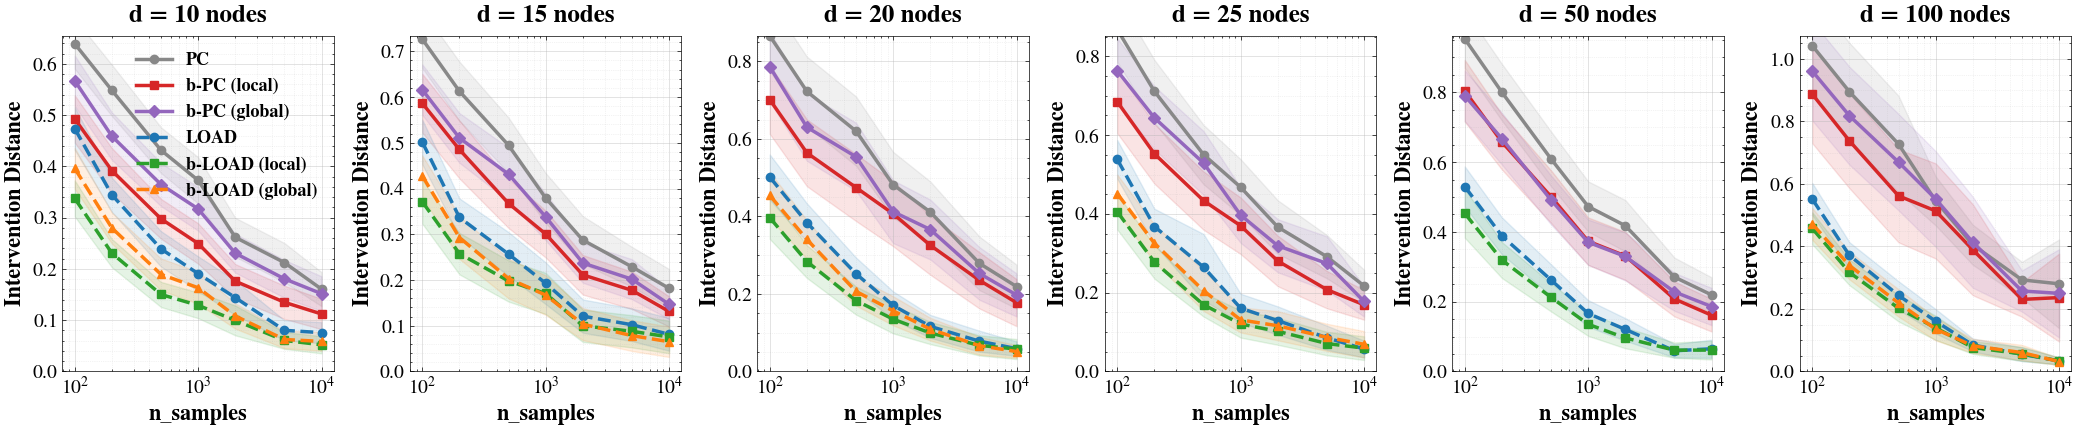

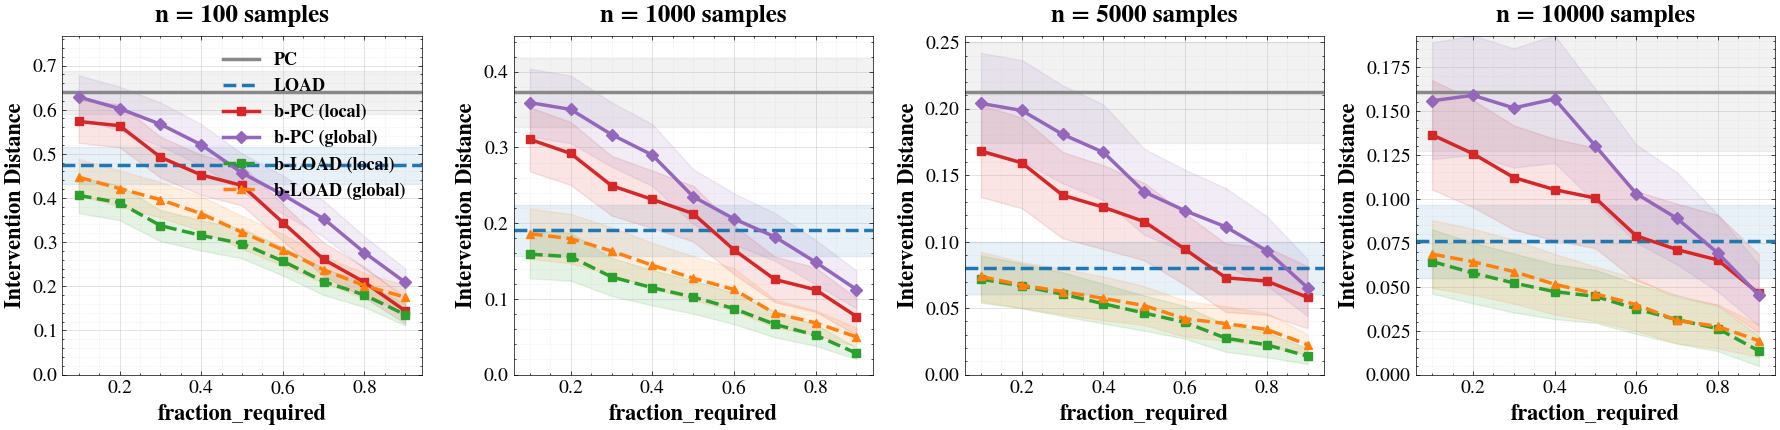

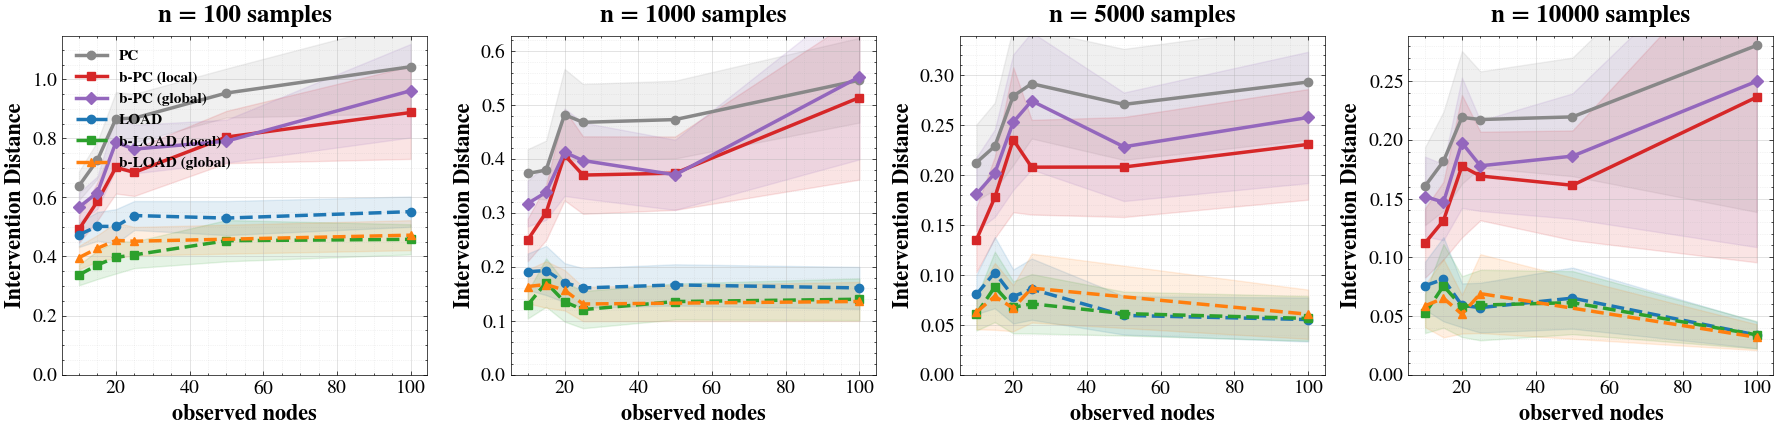

In [16]:
# ══════════════════════════════════════════════════════════════════════════════
#  Intervention Distance — 6 variants, ER2 (Paper-Optimized Sizes)
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ER = 2.0
df_pc_er2    = df_pc         [np.isclose(df_pc         ['exp_degree'], ER)].copy()
df_bpc_er2   = df_bpc        [np.isclose(df_bpc        ['exp_degree'], ER)].copy()
df_bpcg_er2  = df_bpc_global [np.isclose(df_bpc_global ['exp_degree'], ER)].copy()
df_load_er2  = df_load       [np.isclose(df_load       ['exp_degree'], ER)].copy()
df_bglob_er2 = df_bload_global[np.isclose(df_bload_global['exp_degree'], ER)].copy()

COLORS = {
    'pc':          '#888888',
    'bpc':         '#d62728',
    'bpc_glob':    '#9467bd',
    'load':        '#1f77b4',
    'bload_local': '#2ca02c',
    'bload_glob':  '#ff7f0e',
}

def _pline(ax, x, y, ci, color, label, linestyle='-', marker='o', alpha=0.12):
    # Increased linewidth to 2.5 and markersize to 6 for better visibility in print
    ax.plot(x, y, color=color, label=label, linestyle=linestyle,
            marker=marker, markersize=6, linewidth=2.5)
    ax.fill_between(x, y - ci, y + ci, color=color, alpha=alpha)

def _cap_ylim(ax, *series, pct=95, margin=1.20):
    all_vals = [v for s in series for v in s if not np.isnan(v)]
    if all_vals:
        ax.set_ylim(bottom=0, top=np.nanpercentile(all_vals, pct) * margin)

def _fmt(ax, xlabel, xscale='linear', legend_loc='upper right', legend_size=13, show_legend=False):
    # Cranked up axis labels to 16
    ax.set_xlabel(xlabel, fontsize=16, fontweight='bold')
    ax.set_ylabel('Intervention Distance', fontsize=16, fontweight='bold')
    ax.set_xscale(xscale)
    
    # Cranked up tick labels to 14
    ax.tick_params(axis='both', which='major', labelsize=14)
    
    ax.grid(True, which='major', linestyle='-',  alpha=0.5)
    ax.grid(True, which='minor', linestyle=':',  alpha=0.3)
    
    if show_legend:
        ax.legend(framealpha=0.9, loc=legend_loc, prop={'size': legend_size, 'weight': 'bold'})

all_n = sorted(set(df_bpc_er2['n_samples'].unique()) |
               set(df_bpcg_er2['n_samples'].unique()) |
               set(df_bglob_er2['n_samples'].unique()))

# ─────────────────────────────────────────────────────────────────────────────
# A — Data efficiency  |  ER2, frac_req=0.3  |  X: n_samples  |  panels: d
# ─────────────────────────────────────────────────────────────────────────────
FRAC_A = 0.3
D_A = sorted(df_pc_er2['observed'].unique())

# Reduced figsize slightly to force fonts to be larger relative to the plot
fig_a, axes_a = plt.subplots(1, len(D_A), figsize=(3.5 * len(D_A), 4.5), sharey=False)
if len(D_A) == 1: axes_a = [axes_a]

for i, (ax, d) in enumerate(zip(axes_a, D_A)):
    pc_s   = df_pc_er2  [df_pc_er2  ['observed'] == d].sort_values('n_samples')
    bpc_s  = df_bpc_er2 [(df_bpc_er2['observed'] == d) & np.isclose(df_bpc_er2['fraction_required'], FRAC_A)].sort_values('n_samples')
    bpcg_s = df_bpcg_er2[(df_bpcg_er2['observed'] == d) & np.isclose(df_bpcg_er2['fraction_required'], FRAC_A)].sort_values('n_samples')
    lo_s   = df_load_er2[df_load_er2['observed'] == d].drop_duplicates('n_samples').sort_values('n_samples')
    blo_s  = df_load_er2[(df_load_er2['observed'] == d) & np.isclose(df_load_er2['fraction_required'], FRAC_A)].sort_values('n_samples')
    bgl_s  = df_bglob_er2[(df_bglob_er2['observed'] == d) & np.isclose(df_bglob_er2['fraction_required'], FRAC_A)].sort_values('n_samples')

    _pline(ax, pc_s['n_samples'], pc_s['int_dist_mean'], pc_s['ci_int_dist'],
           COLORS['pc'],    'PC',             '-',  'o')
    if not bpc_s.empty:
        _pline(ax, bpc_s['n_samples'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],   'b-PC (local)',   '-',  's')
    if not bpcg_s.empty:
        _pline(ax, bpcg_s['n_samples'], bpcg_s['int_dist_mean'], bpcg_s['ci_int_dist'],
               COLORS['bpc_glob'], 'b-PC (global)', '-',  'D')
    _pline(ax, lo_s['n_samples'], lo_s['int_dist_without_b_mean'], lo_s['ci_int_dist_without_b'],
           COLORS['load'],  'LOAD',            '--', 'o')
    if not blo_s.empty:
        _pline(ax, blo_s['n_samples'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', '--', 's')
    if not bgl_s.empty:
        _pline(ax, bgl_s['n_samples'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', '--', '^')

    _cap_ylim(ax, pc_s['int_dist_mean'], lo_s['int_dist_without_b_mean'],
              bpc_s['int_dist_mean'] if not bpc_s.empty else [],
              bpcg_s['int_dist_mean'] if not bpcg_s.empty else [],
              blo_s['int_dist_with_b_mean'] if not blo_s.empty else [],
              bgl_s['int_dist_with_b_mean'] if not bgl_s.empty else [])
    
    # Title bumped to 18
    ax.set_title(f'd = {d} nodes', fontsize=18, fontweight='bold', pad=10)
    _fmt(ax, 'n_samples', xscale='log', show_legend=(i == 0))

plt.tight_layout()
plt.savefig('int_dist_A_v2.pdf', bbox_inches='tight')
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# B — BK sensitivity  |  ER2, d=10  |  X: frac_req  |  panels: n_samples
# ─────────────────────────────────────────────────────────────────────────────
D_B = 10
N_B = [n for n in [100, 1000, 5000, 10000] if n in all_n]

fig_b, axes_b = plt.subplots(1, len(N_B), figsize=(4.5 * len(N_B), 4.5), sharey=False)
if len(N_B) == 1: axes_b = [axes_b]

for i, (ax, n) in enumerate(zip(axes_b, N_B)):
    pc_row  = df_pc_er2  [(df_pc_er2  ['observed'] == D_B) & (df_pc_er2  ['n_samples'] == n)]
    bpc_s   = df_bpc_er2 [(df_bpc_er2 ['observed'] == D_B) & (df_bpc_er2 ['n_samples'] == n)].sort_values('fraction_required')
    bpcg_s  = df_bpcg_er2[(df_bpcg_er2['observed'] == D_B) & (df_bpcg_er2['n_samples'] == n)].sort_values('fraction_required')
    lo_rows = df_load_er2[(df_load_er2['observed'] == D_B) & (df_load_er2['n_samples'] == n)]
    lo_row  = lo_rows.drop_duplicates('n_samples')
    blo_s   = lo_rows.sort_values('fraction_required')
    bgl_s   = df_bglob_er2[(df_bglob_er2['observed'] == D_B) & (df_bglob_er2['n_samples'] == n)].sort_values('fraction_required')

    if not pc_row.empty:
        py, pci = pc_row['int_dist_mean'].iloc[0], pc_row['ci_int_dist'].iloc[0]
        ax.axhline(py, color=COLORS['pc'], lw=2.5, ls='-', label='PC')
        ax.axhspan(py - pci, py + pci, color=COLORS['pc'], alpha=0.10)
    if not lo_row.empty:
        ly, lci = lo_row['int_dist_without_b_mean'].iloc[0], lo_row['ci_int_dist_without_b'].iloc[0]
        ax.axhline(ly, color=COLORS['load'], lw=2.5, ls='--', label='LOAD')
        ax.axhspan(ly - lci, ly + lci, color=COLORS['load'], alpha=0.10)

    if not bpc_s.empty:
        _pline(ax, bpc_s['fraction_required'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],       'b-PC (local)',    '-',  's')
    if not bpcg_s.empty:
        _pline(ax, bpcg_s['fraction_required'], bpcg_s['int_dist_mean'], bpcg_s['ci_int_dist'],
               COLORS['bpc_glob'],  'b-PC (global)',   '-',  'D')
    if not blo_s.empty:
        _pline(ax, blo_s['fraction_required'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', '--', 's')
    if not bgl_s.empty:
        _pline(ax, bgl_s['fraction_required'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', '--', '^')

    _cap_ylim(ax,
              pc_row['int_dist_mean']          if not pc_row.empty else [],
              lo_row['int_dist_without_b_mean'] if not lo_row.empty else [],
              bpc_s ['int_dist_mean']           if not bpc_s.empty  else [],
              bpcg_s['int_dist_mean']           if not bpcg_s.empty else [],
              blo_s ['int_dist_with_b_mean']    if not blo_s.empty  else [],
              bgl_s ['int_dist_with_b_mean']    if not bgl_s.empty  else [],
              pct=100)
    
    # Title bumped to 18
    ax.set_title(f'n = {n} samples', fontsize=18, fontweight='bold', pad=10)
    _fmt(ax, 'fraction_required', show_legend=(i == 0))

plt.tight_layout()
plt.savefig('int_dist_B_v2.pdf', bbox_inches='tight')
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# C — Scalability  |  ER2, frac_req=0.3  |  X: observed  |  panels: n_samples
# ─────────────────────────────────────────────────────────────────────────────
FRAC_C = 0.3
N_C = [n for n in [100, 1000, 5000, 10000] if n in all_n]

fig_c, axes_c = plt.subplots(1, len(N_C), figsize=(4.5 * len(N_C), 4.5), sharey=False)
if len(N_C) == 1: axes_c = [axes_c]

for i, (ax, n) in enumerate(zip(axes_c, N_C)):
    pc_s   = df_pc_er2  [df_pc_er2  ['n_samples'] == n].sort_values('observed')
    bpc_s  = df_bpc_er2 [(df_bpc_er2['n_samples'] == n) & np.isclose(df_bpc_er2['fraction_required'], FRAC_C)].sort_values('observed')
    bpcg_s = df_bpcg_er2[(df_bpcg_er2['n_samples'] == n) & np.isclose(df_bpcg_er2['fraction_required'], FRAC_C)].sort_values('observed')
    lo_s   = df_load_er2[df_load_er2['n_samples'] == n].drop_duplicates('observed').sort_values('observed')
    blo_s  = df_load_er2[(df_load_er2['n_samples'] == n) & np.isclose(df_load_er2['fraction_required'], FRAC_C)].sort_values('observed')
    bgl_s  = df_bglob_er2[(df_bglob_er2['n_samples'] == n) & np.isclose(df_bglob_er2['fraction_required'], FRAC_C)].sort_values('observed')

    _pline(ax, pc_s['observed'], pc_s['int_dist_mean'], pc_s['ci_int_dist'],
           COLORS['pc'],    'PC',             '-',  'o')
    if not bpc_s.empty:
        _pline(ax, bpc_s['observed'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],   'b-PC (local)',   '-',  's')
    if not bpcg_s.empty:
        _pline(ax, bpcg_s['observed'], bpcg_s['int_dist_mean'], bpcg_s['ci_int_dist'],
               COLORS['bpc_glob'], 'b-PC (global)', '-',  'D')
    _pline(ax, lo_s['observed'], lo_s['int_dist_without_b_mean'], lo_s['ci_int_dist_without_b'],
           COLORS['load'],  'LOAD',            '--', 'o')
    if not blo_s.empty:
        _pline(ax, blo_s['observed'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', '--', 's')
    if not bgl_s.empty:
        _pline(ax, bgl_s['observed'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', '--', '^')

    _cap_ylim(ax, pc_s['int_dist_mean'], lo_s['int_dist_without_b_mean'],
              bpc_s['int_dist_mean']  if not bpc_s.empty  else [],
              bpcg_s['int_dist_mean'] if not bpcg_s.empty else [],
              blo_s['int_dist_with_b_mean']  if not blo_s.empty  else [],
              bgl_s['int_dist_with_b_mean']  if not bgl_s.empty  else [])
    
    # Title bumped to 18
    ax.set_title(f'n = {n} samples', fontsize=18, fontweight='bold', pad=10)
    
    # Adjusted legend size to 11 here (up from 8) so it stays readable but avoids overlap
    _fmt(ax, 'observed nodes', legend_loc='upper left', legend_size=11, show_legend=(i == 0))

plt.tight_layout()
plt.savefig('int_dist_C_v2.pdf', bbox_inches='tight')
plt.show()

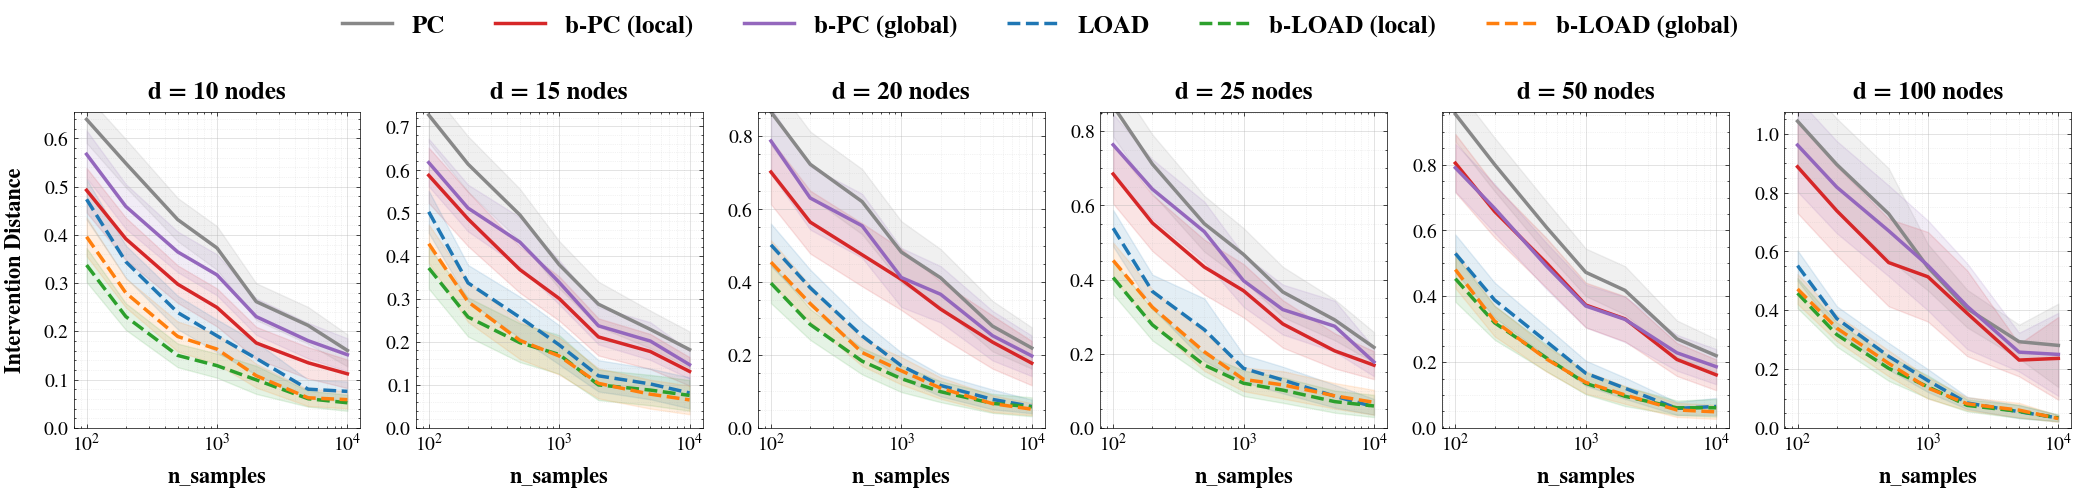

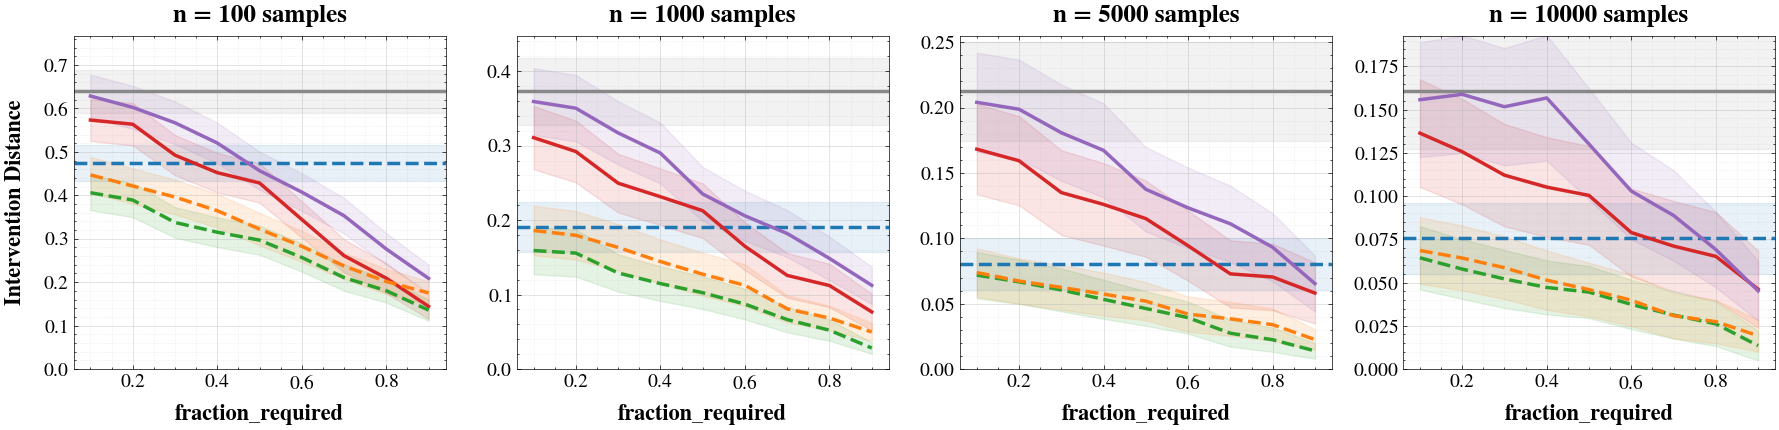

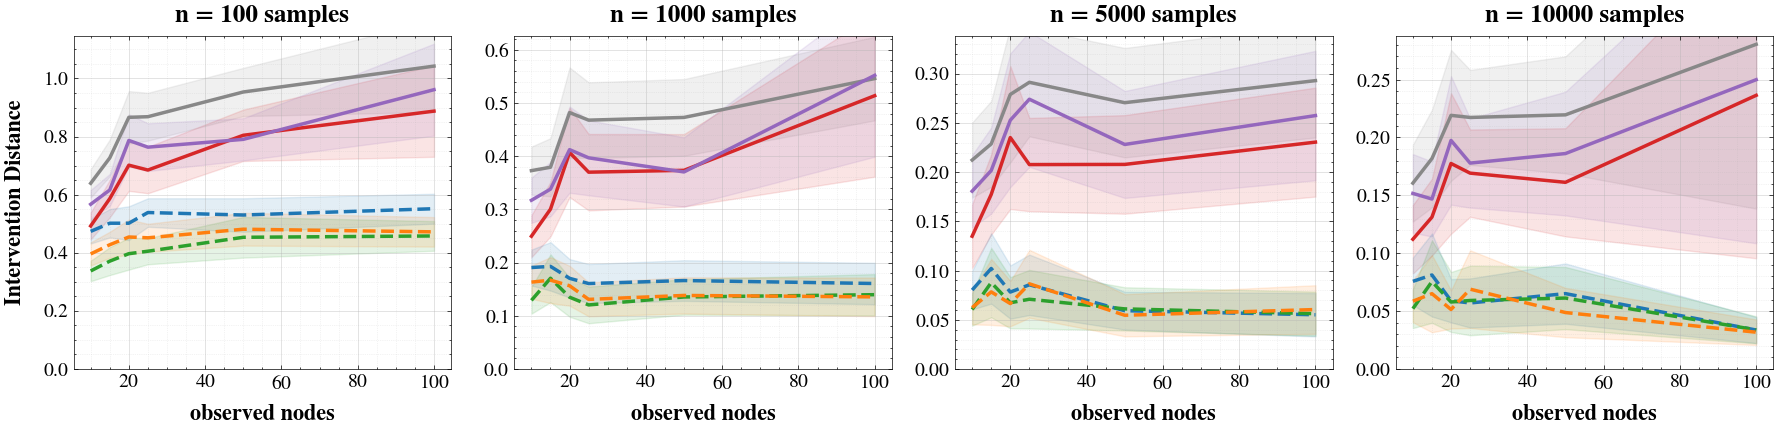

In [16]:
# ══════════════════════════════════════════════════════════════════════════════
#  Intervention Distance — 6 variants, ER2 (Clean Lines, No Markers)
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ER = 2.0
df_pc_er2    = df_pc         [np.isclose(df_pc         ['exp_degree'], ER)].copy()
df_bpc_er2   = df_bpc        [np.isclose(df_bpc        ['exp_degree'], ER)].copy()
df_bpcg_er2  = df_bpc_global [np.isclose(df_bpc_global ['exp_degree'], ER)].copy()
df_load_er2  = df_load       [np.isclose(df_load       ['exp_degree'], ER)].copy()
df_bglob_er2 = df_bload_global[np.isclose(df_bload_global['exp_degree'], ER)].copy()

COLORS = {
    'pc':          '#888888',
    'bpc':         '#d62728',
    'bpc_glob':    '#9467bd',
    'load':        '#1f77b4',
    'bload_local': '#2ca02c',
    'bload_glob':  '#ff7f0e',
}

# Removed the 'marker' and 'markersize' arguments entirely
def _pline(ax, x, y, ci, color, label, linestyle='-', alpha=0.12):
    ax.plot(x, y, color=color, label=label, linestyle=linestyle, linewidth=2.5)
    ax.fill_between(x, y - ci, y + ci, color=color, alpha=alpha)

def _cap_ylim(ax, *series, pct=95, margin=1.20):
    all_vals = [v for s in series for v in s if not np.isnan(v)]
    if all_vals:
        ax.set_ylim(bottom=0, top=np.nanpercentile(all_vals, pct) * margin)

def _fmt(ax, xlabel, xscale='linear', show_ylabel=False):
    ax.set_xlabel(xlabel, fontsize=16, fontweight='bold', labelpad=8)
    
    if show_ylabel:
        ax.set_ylabel('Intervention Distance', fontsize=16, fontweight='bold', labelpad=12)
        
    ax.set_xscale(xscale)
    ax.tick_params(axis='both', which='major', labelsize=14)
    
    ax.grid(True, which='major', linestyle='-',  alpha=0.5)
    ax.grid(True, which='minor', linestyle=':',  alpha=0.3)

all_n = sorted(set(df_bpc_er2['n_samples'].unique()) |
               set(df_bpcg_er2['n_samples'].unique()) |
               set(df_bglob_er2['n_samples'].unique()))

# ─────────────────────────────────────────────────────────────────────────────
# A — Data efficiency  |  ER2, frac_req=0.3  |  X: n_samples  |  panels: d
# ─────────────────────────────────────────────────────────────────────────────
FRAC_A = 0.3
D_A = sorted(df_pc_er2['observed'].unique())

fig_a, axes_a = plt.subplots(1, len(D_A), figsize=(3.5 * len(D_A), 5.0), sharey=False)
if len(D_A) == 1: axes_a = [axes_a]

for i, (ax, d) in enumerate(zip(axes_a, D_A)):
    pc_s   = df_pc_er2  [df_pc_er2  ['observed'] == d].sort_values('n_samples')
    bpc_s  = df_bpc_er2 [(df_bpc_er2['observed'] == d) & np.isclose(df_bpc_er2['fraction_required'], FRAC_A)].sort_values('n_samples')
    bpcg_s = df_bpcg_er2[(df_bpcg_er2['observed'] == d) & np.isclose(df_bpcg_er2['fraction_required'], FRAC_A)].sort_values('n_samples')
    lo_s   = df_load_er2[df_load_er2['observed'] == d].drop_duplicates('n_samples').sort_values('n_samples')
    blo_s  = df_load_er2[(df_load_er2['observed'] == d) & np.isclose(df_load_er2['fraction_required'], FRAC_A)].sort_values('n_samples')
    bgl_s  = df_bglob_er2[(df_bglob_er2['observed'] == d) & np.isclose(df_bglob_er2['fraction_required'], FRAC_A)].sort_values('n_samples')

    # Cleaned up all function calls to exclude the marker argument
    _pline(ax, pc_s['n_samples'], pc_s['int_dist_mean'], pc_s['ci_int_dist'],
           COLORS['pc'],    'PC',             '-')
    if not bpc_s.empty:
        _pline(ax, bpc_s['n_samples'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],   'b-PC (local)',   '-')
    if not bpcg_s.empty:
        _pline(ax, bpcg_s['n_samples'], bpcg_s['int_dist_mean'], bpcg_s['ci_int_dist'],
               COLORS['bpc_glob'], 'b-PC (global)', '-')
    _pline(ax, lo_s['n_samples'], lo_s['int_dist_without_b_mean'], lo_s['ci_int_dist_without_b'],
           COLORS['load'],  'LOAD',            '--')
    if not blo_s.empty:
        _pline(ax, blo_s['n_samples'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', '--')
    if not bgl_s.empty:
        _pline(ax, bgl_s['n_samples'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', '--')

    _cap_ylim(ax, pc_s['int_dist_mean'], lo_s['int_dist_without_b_mean'],
              bpc_s['int_dist_mean'] if not bpc_s.empty else [],
              bpcg_s['int_dist_mean'] if not bpcg_s.empty else [],
              blo_s['int_dist_with_b_mean'] if not blo_s.empty else [],
              bgl_s['int_dist_with_b_mean'] if not bgl_s.empty else [])
    
    ax.set_title(f'd = {d} nodes', fontsize=18, fontweight='bold', pad=10)
    _fmt(ax, 'n_samples', xscale='log', show_ylabel=(i == 0))


# 1. Apply tight layout first
plt.tight_layout(w_pad=1.5)

# 2. Force a larger margin at the top of the entire figure (reserves the top 22% of space)
fig_a.subplots_adjust(top=0.78)

# 3. Anchor the legend firmly inside that reserved space with a bigger font size
handles, labels = axes_a[0].get_legend_handles_labels()
fig_a.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.02), 
             ncol=6, prop={'size': 18, 'weight': 'bold'}, frameon=False)

plt.savefig('int_dist_A_v2.pdf', bbox_inches='tight')
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# B — BK sensitivity  |  ER2, d=10  |  X: frac_req  |  panels: n_samples
# ─────────────────────────────────────────────────────────────────────────────
D_B = 10
N_B = [n for n in [100, 1000, 5000, 10000] if n in all_n]

fig_b, axes_b = plt.subplots(1, len(N_B), figsize=(4.5 * len(N_B), 4.5), sharey=False)
if len(N_B) == 1: axes_b = [axes_b]

for i, (ax, n) in enumerate(zip(axes_b, N_B)):
    pc_row  = df_pc_er2  [(df_pc_er2  ['observed'] == D_B) & (df_pc_er2  ['n_samples'] == n)]
    bpc_s   = df_bpc_er2 [(df_bpc_er2 ['observed'] == D_B) & (df_bpc_er2 ['n_samples'] == n)].sort_values('fraction_required')
    bpcg_s  = df_bpcg_er2[(df_bpcg_er2['observed'] == D_B) & (df_bpcg_er2['n_samples'] == n)].sort_values('fraction_required')
    lo_rows = df_load_er2[(df_load_er2['observed'] == D_B) & (df_load_er2['n_samples'] == n)]
    lo_row  = lo_rows.drop_duplicates('n_samples')
    blo_s   = lo_rows.sort_values('fraction_required')
    bgl_s   = df_bglob_er2[(df_bglob_er2['observed'] == D_B) & (df_bglob_er2['n_samples'] == n)].sort_values('fraction_required')

    if not pc_row.empty:
        py, pci = pc_row['int_dist_mean'].iloc[0], pc_row['ci_int_dist'].iloc[0]
        ax.axhline(py, color=COLORS['pc'], lw=2.5, ls='-', label='PC')
        ax.axhspan(py - pci, py + pci, color=COLORS['pc'], alpha=0.10)
    if not lo_row.empty:
        ly, lci = lo_row['int_dist_without_b_mean'].iloc[0], lo_row['ci_int_dist_without_b'].iloc[0]
        ax.axhline(ly, color=COLORS['load'], lw=2.5, ls='--', label='LOAD')
        ax.axhspan(ly - lci, ly + lci, color=COLORS['load'], alpha=0.10)

    # Cleaned up all function calls
    if not bpc_s.empty:
        _pline(ax, bpc_s['fraction_required'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],       'b-PC (local)',    '-')
    if not bpcg_s.empty:
        _pline(ax, bpcg_s['fraction_required'], bpcg_s['int_dist_mean'], bpcg_s['ci_int_dist'],
               COLORS['bpc_glob'],  'b-PC (global)',   '-')
    if not blo_s.empty:
        _pline(ax, blo_s['fraction_required'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', '--')
    if not bgl_s.empty:
        _pline(ax, bgl_s['fraction_required'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', '--')

    _cap_ylim(ax,
              pc_row['int_dist_mean']          if not pc_row.empty else [],
              lo_row['int_dist_without_b_mean'] if not lo_row.empty else [],
              bpc_s ['int_dist_mean']           if not bpc_s.empty  else [],
              bpcg_s['int_dist_mean']           if not bpcg_s.empty else [],
              blo_s ['int_dist_with_b_mean']    if not blo_s.empty  else [],
              bgl_s ['int_dist_with_b_mean']    if not bgl_s.empty  else [],
              pct=100)
    
    ax.set_title(f'n = {n} samples', fontsize=18, fontweight='bold', pad=10)
    _fmt(ax, 'fraction_required', show_ylabel=(i == 0))

plt.tight_layout(w_pad=1.5)
plt.savefig('int_dist_B_v2.pdf', bbox_inches='tight')
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# C — Scalability  |  ER2, frac_req=0.3  |  X: observed  |  panels: n_samples
# ─────────────────────────────────────────────────────────────────────────────
FRAC_C = 0.3
N_C = [n for n in [100, 1000, 5000, 10000] if n in all_n]

fig_c, axes_c = plt.subplots(1, len(N_C), figsize=(4.5 * len(N_C), 4.5), sharey=False)
if len(N_C) == 1: axes_c = [axes_c]

for i, (ax, n) in enumerate(zip(axes_c, N_C)):
    pc_s   = df_pc_er2  [df_pc_er2  ['n_samples'] == n].sort_values('observed')
    bpc_s  = df_bpc_er2 [(df_bpc_er2['n_samples'] == n) & np.isclose(df_bpc_er2['fraction_required'], FRAC_C)].sort_values('observed')
    bpcg_s = df_bpcg_er2[(df_bpcg_er2['n_samples'] == n) & np.isclose(df_bpcg_er2['fraction_required'], FRAC_C)].sort_values('observed')
    lo_s   = df_load_er2[df_load_er2['n_samples'] == n].drop_duplicates('observed').sort_values('observed')
    blo_s  = df_load_er2[(df_load_er2['n_samples'] == n) & np.isclose(df_load_er2['fraction_required'], FRAC_C)].sort_values('observed')
    bgl_s  = df_bglob_er2[(df_bglob_er2['n_samples'] == n) & np.isclose(df_bglob_er2['fraction_required'], FRAC_C)].sort_values('observed')

    # Cleaned up all function calls
    _pline(ax, pc_s['observed'], pc_s['int_dist_mean'], pc_s['ci_int_dist'],
           COLORS['pc'],    'PC',             '-')
    if not bpc_s.empty:
        _pline(ax, bpc_s['observed'], bpc_s['int_dist_mean'], bpc_s['ci_int_dist'],
               COLORS['bpc'],   'b-PC (local)',   '-')
    if not bpcg_s.empty:
        _pline(ax, bpcg_s['observed'], bpcg_s['int_dist_mean'], bpcg_s['ci_int_dist'],
               COLORS['bpc_glob'], 'b-PC (global)', '-')
    _pline(ax, lo_s['observed'], lo_s['int_dist_without_b_mean'], lo_s['ci_int_dist_without_b'],
           COLORS['load'],  'LOAD',            '--')
    if not blo_s.empty:
        _pline(ax, blo_s['observed'], blo_s['int_dist_with_b_mean'], blo_s['ci_int_dist_with_b'],
               COLORS['bload_local'], 'b-LOAD (local)', '--')
    if not bgl_s.empty:
        _pline(ax, bgl_s['observed'], bgl_s['int_dist_with_b_mean'], bgl_s['ci_int_dist_with_b'],
               COLORS['bload_glob'],  'b-LOAD (global)', '--')

    _cap_ylim(ax, pc_s['int_dist_mean'], lo_s['int_dist_without_b_mean'],
              bpc_s['int_dist_mean']  if not bpc_s.empty  else [],
              bpcg_s['int_dist_mean'] if not bpcg_s.empty else [],
              blo_s['int_dist_with_b_mean']  if not blo_s.empty  else [],
              bgl_s['int_dist_with_b_mean']  if not bgl_s.empty  else [])
    
    ax.set_title(f'n = {n} samples', fontsize=18, fontweight='bold', pad=10)
    _fmt(ax, 'observed nodes', show_ylabel=(i == 0))

plt.tight_layout(w_pad=1.5)
plt.savefig('int_dist_C_v2.pdf', bbox_inches='tight')
plt.show()